# CNN-1 · 합성곱과 크기 계산

**한 줄 요약** · 같은 모양이 다른 위치에 있어도 CNN이 알아보는 이유(같은 창을 옮겨 쓰기)와, 층마다 출력 크기 · 채널 · 파라미터가 정해지는 규칙을 손으로 계산하고 코드로 확인함

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. `(N, C, H, W)` 이미지 텐서의 각 축을 말하고, 번호로 집을 때와 범위로 자를 때의 shape를 미리 말한다
2. 펴서 넣는 모델(Dense)이 옮긴 모양을 다시 배워야 하는 이유를 숫자(9점 → 2점)로 설명한다
3. 3×3 창 하나의 합성곱 값을 손으로 계산해 `F.conv2d` 결과와 맞춘다
4. 출력 크기 `(W - K + 2P) // S + 1`과 `nn.Conv2d`의 weight 모양 · 파라미터 수를 손계산하고 코드로 검증한다
5. 같은 파라미터 수의 CNN과 MLP를 학습해 정확도 · 옮긴 이미지 정확도 차이를 설명한다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **이미지 분류 모델을 직접 설계할 때** · 층마다 출력 크기 · 파라미터 수 계산 (6 · 7장)
- **`mat1 and mat2 shapes cannot be multiplied` 에러를 만났을 때** · Flatten 길이 = Linear 입력 길이 (3장)
- **사전학습 모델에 흑백 사진을 넣을 때** · 채널 맞추기 · ToTensor (1장)
- **학습 코드가 제대로 연결됐는지 확인할 때** · 첫 loss ≈ 2.3 점검 · 같은 배치 반복 (3장)

## 학습 지도

<img src="images/cnn1_map.png" alt="CNN-1 학습 지도" width="837">

**예상 학습 시간** · 개념 2시간 + 실습 1시간 (GPU가 없어도 8장 학습은 몇 분 안에 끝남)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;">0</td><td>준비</td><td>라이브러리 · seed · 실행 장치 · MNIST</td></tr>
<tr><td style="text-align: center;">1</td><td>이미지 텐서</td><td>이미지는 컴퓨터에게 어떤 모양이고, 채널은 무엇인가?</td></tr>
<tr><td style="text-align: center;">2</td><td>데이터 공급</td><td>6만 장은 언제 변환되고, 배치는 몇 개인가?</td></tr>
<tr><td style="text-align: center;">3</td><td>펴서 분류하기와 첫 점검</td><td>펴서 넣으면 무엇을 잃고, 첫 loss 2.3은 무엇을 점검하나?</td></tr>
<tr><td style="text-align: center;">4</td><td>Dense의 위치 문제</td><td>옮긴 모양을 Dense는 왜 다시 배우고, 합성곱은 무엇이 다른가?</td></tr>
<tr><td style="text-align: center;">5</td><td>합성곱 계산</td><td>창 하나는 숫자 하나를 어떻게 만드는가?</td></tr>
<tr><td style="text-align: center;">6</td><td>출력 크기</td><td>stride · padding을 바꾸면 크기는 어떻게 되나?</td></tr>
<tr><td style="text-align: center;">7</td><td>채널 · 필터 · weight</td><td>컬러 입력의 필터 모양과 파라미터 수는?</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;">8</td><td>종합 실습</td><td>같은 예산에서 CNN과 MLP는 어떻게 다른가?</td></tr>
<tr><td style="text-align: center;">—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

모든 장에서 쓰는 라이브러리를 불러오고, 난수 seed · cuDNN 결정적 설정 · 실행 장치를 정한 뒤 MNIST를 내려받음. **셀은 위에서부터 차례로 실행**(앞 섹션의 변수를 이어서 씀).

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">설정</th><th style="text-align: left;">내용</th><th style="text-align: left;">이유</th></tr>
</thead>
<tbody>
<tr><td><code>torch.manual_seed(0)</code></td><td>난수 seed 고정</td><td>같은 환경에서 다시 실행하면 같은 결과 (난수를 쓰는 셀은 셀 안에서 다시 고정)</td></tr>
<tr><td><code>cudnn.deterministic = True</code> · <code>benchmark = False</code></td><td>같은 GPU · 같은 버전에서 합성곱도 매번 같은 알고리즘</td><td>GPU에서 두 번 실행해도 같은 값</td></tr>
<tr><td><code>device</code></td><td>GPU가 있으면 <code>cuda</code>, 없으면 <code>cpu</code></td><td>GPU 없는 PC에서도 코드 수정 없이 실행 (CPU 실행도 확인함, 학습 결과는 소수 셋째 자리만 다름 · Mac은 슬라이드처럼 <code>mps</code> 추가 가능)</td></tr>
<tr><td><code>datasets.MNIST("data", download=True)</code></td><td>노트북 옆 <code>data/</code> 폴더에 한 번만 내려받음</td><td>이 폴더는 GitHub에 올리지 않음</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">데이터</th><th style="text-align: left;">내용</th><th style="text-align: left;">처음 나오는 곳</th></tr>
</thead>
<tbody>
<tr><td><code>cross</code> · <code>moved</code></td><td>7×7 십자 · 한 칸 옮긴 십자</td><td>1-1</td></tr>
<tr><td><code>train_full</code> · <code>test_full</code></td><td>MNIST 학습 60,000장 · 테스트 10,000장 <code>(1, 28, 28)</code> · 정답 0 ~ 9</td><td>0</td></tr>
<tr><td><code>images</code> · <code>labels</code></td><td>1,000장에서 꺼낸 배치 64장</td><td>2-2</td></tr>
<tr><td><code>x5</code> · <code>k3</code></td><td>슬라이드 손계산용 5×5 입력 · <code>[1, 0, -1]</code> 커널</td><td>5-1</td></tr>
<tr><td><code>rgb</code></td><td>슬라이드의 3채널 5×5 입력</td><td>7-1</td></tr>
<tr><td><code>train_set</code> · <code>test_set</code></td><td>MNIST 학습 5,000장 · 테스트 2,000장 부분집합</td><td>8</td></tr>
</tbody></table>

**실행 흐름**

1. 도구 불러오기 · OpenMP 충돌 방지
2. seed · 결정적 알고리즘 · 장치 정하기
3. MNIST 내려받기(처음 한 번)

In [1]:
# 라이브러리 불러오기
# 왜 · 이 노트북 전체에서 쓰는 도구를 한곳에 모아 두기 위해
import math  # log(10) → 첫 loss 기댓값
import os    # 환경 변수 (아래 OpenMP 설정)

import numpy as np                               # 사진 파일을 읽은 배열 (H, W, C) 흉내
import torch                                     # 텐서 · 자동 미분
import torch.nn as nn                            # 층: Conv2d · Linear · Flatten · ReLU
import torch.nn.functional as F                  # 함수: conv2d · cross_entropy
from torch.utils.data import DataLoader, Subset  # 배치 공급 · 일부만
from torchvision import datasets, transforms     # MNIST · ToTensor


# torch와 matplotlib(8장 그래프)을 한 커널에서 쓸 때 OpenMP 충돌 방지
# 왜 · 그래프를 그릴 때 커널이 멈추는 충돌을 미리 막기 위해
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # 충돌 경고로 커널이 죽지 않게


# 재현성: seed 고정 + cuDNN 결정적 알고리즘 (같은 GPU · 같은 버전에서 매번 같은 값)
# 왜 · 같은 환경에서 다시 실행해도 같은 숫자가 나와 설명과 출력을 맞추기 위해
torch.manual_seed(0)                       # 난수 기준값 고정 → 같은 환경에서 같은 결과
torch.backends.cudnn.deterministic = True  # 같은 GPU · 같은 버전에서 합성곱도 매번 같은 값
torch.backends.cudnn.benchmark = False     # 실행마다 계산 방법이 바뀌지 않게


# 실행 장치: GPU가 있으면 cuda, 없으면 cpu (코드는 그대로)
# 왜 · GPU 유무와 상관없이 같은 코드로 실행되게 하기 위해
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # 쓸 장치 고르기
print("PyTorch:", torch.__version__.split("+")[0])                     # 설치된 버전 기록
print("실행 장치:", device.type)                                       # cuda인지 cpu인지 확인


# MNIST 손글씨 숫자: 처음 한 번만 data/ 폴더에 내려받음 (약 60MB)
# 왜 · 인터넷은 처음 한 번만 쓰고 그다음부터는 data/의 파일을 그대로 쓰기 위해
to_tensor = transforms.ToTensor()                               # 사진 → 텐서 변환기 (1-4)
train_full = datasets.MNIST("data", train=True, download=True,  # 학습용 6만 장
                            transform=to_tensor)
test_full = datasets.MNIST("data", train=False, download=True,  # 테스트용 1만 장
                           transform=to_tensor)
print("학습:", len(train_full), "| 테스트:", len(test_full))    # 받은 장수 확인

PyTorch: 2.11.0
실행 장치: cuda
학습: 60000 | 테스트: 10000


---
## 1. 이미지 텐서

> **이 장의 흐름**
>
> - 딥러닝기초-1에서 텐서의 shape · dtype · device를 배움
> - 이미지는 축이 4개 `(N, C, H, W)`인 텐서.
> - 모델이 이미지를 어떤 숫자로 받는지, 채널은 무엇인지, 사진 파일이 어떻게 텐서가 되는지를 먼저 확인

**파이프라인 위치** · ① 데이터 준비 · ③ 전처리 — 이미지 = 값 + 자리, `ToTensor`

### 1-1. `A` 값과 자리 · `torch.zeros()` · `!=` <sub>DAY01 5~9쪽</sub>

> 🎯 **이미지 한 장은 컴퓨터에게 무엇이고, 같은 십자를 한 칸 옮기면 숫자로는 얼마나 달라지는가?**

💡 **쉽게 말하면**

- 이미지는 **숫자가 놓인 자리표**.
- 사람은 모양을 보지만 컴퓨터는 "몇 번 자리에 어떤 값"만 받으므로, 같은 값이라도 자리가 바뀌면 다른 표가 됨.

**실행 흐름**

1. 7×7 십자 그리기
2. 오른쪽 아래로 한 칸 이동
3. 두 격자 나란히 출력
4. 값 개수 · 값 모음 · 다른 자리 수 비교

**먼저 예측** · 1이 9개인 십자를 한 칸 옮기면 49자리 중 몇 자리의 값이 달라질까? — 답은 코드 실행 결과 아래에

In [2]:
# 7×7 격자에 십자 그리기: 값 1 = 밝음, 0 = 어두움
# 왜 · 위치 차이를 눈으로 확인할 가장 작은 그림을 만들기 위해
cross = torch.zeros(7, 7)  # 0으로 채운 7×7 = 검은 바탕
cross[1:6, 2] = 1          # 2번 열의 1 ~ 5행 → 세로 막대
cross[3, 1:6] = 1          # 3번 행의 1 ~ 5열 → 가로 막대


# 같은 십자를 오른쪽 아래로 한 칸 옮기기
# 왜 · 사람에겐 같은 모양인데 숫자 배열은 달라지는 상황을 만들기 위해
moved = torch.zeros(7, 7)                                             # 옮길 자리도 검은 바탕부터
moved[1:, 1:] = cross[:-1, :-1]                                       # 원래 (i, j) → 새 (i+1, j+1)
for row_a, row_b in zip(cross.int().tolist(), moved.int().tolist()):  # 두 격자를 한 줄씩 짝지어
    print(*row_a, "  |  ", *row_b)                                    # 나란히 출력해 눈으로 비교


# 값만 모으면 같음 · 자리까지 보면 다름
# 왜 · 이미지에서는 값뿐 아니라 자리가 중요하다는 것을 확인하기 위해
print("1의 개수:", int(cross.sum()), int(moved.sum()))         # 밝은 칸 수 = 값의 개수
same = torch.equal(cross.flatten().sort().values,              # 값만 정렬해 비교
                   moved.flatten().sort().values)              # 자리 무시 → 값만
print("값 모음이 같음:", same)                                 # 자리 무시하면 같은지
print("값이 다른 자리:", int((cross != moved).sum()), "/ 49")  # 자리별로 다른 칸 수

0 0 0 0 0 0 0   |   0 0 0 0 0 0 0
0 0 1 0 0 0 0   |   0 0 0 0 0 0 0
0 0 1 0 0 0 0   |   0 0 0 1 0 0 0
0 1 1 1 1 1 0   |   0 0 0 1 0 0 0
0 0 1 0 0 0 0   |   0 0 1 1 1 1 1
0 0 1 0 0 0 0   |   0 0 0 1 0 0 0
0 0 0 0 0 0 0   |   0 0 0 1 0 0 0
1의 개수: 9 9
값 모음이 같음: True
값이 다른 자리: 14 / 49


**결과** · 예측 정답은 `14` — 원래 9자리에서 1이 사라지고 새 9자리에 생기는데, 겹치는 2자리를 빼면 7 + 7 = 14

- `0 1 1 1 1 1 0 | 0 0 0 1 0 0 0` — 4번째 줄: 왼쪽은 가로 막대, 오른쪽은 가로 막대가 한 줄 아래로 내려가 세로 막대만 지남
- `1의 개수: 9 9` — 값의 개수는 그대로
- `값 모음이 같음: True` — 자리를 무시하고 값만 정렬해 모으면 완전히 같음
- `값이 다른 자리: 14 / 49` — 자리까지 보면 14자리가 어긋남 → 숫자 표로는 다른 이미지

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>값 (밝기)</td><td>그 자리가 얼마나 밝은가 · 전처리로 범위가 바뀜</td><td>정규화 · 대비 조정을 할 때</td></tr>
<tr><td>자리 (위치)</td><td>몇 번째 행 · 열인가 · 이웃 관계를 담음</td><td>모양 · 경계를 찾을 때 (합성곱이 쓰는 정보)</td></tr>
<tr><td>값 모음 비교 (정렬 뒤)</td><td>자리를 무시 → 옮긴 십자와 <strong>같다</strong>고 판단</td><td>밝기 분포(히스토그램)를 볼 때</td></tr>
<tr><td>자리별 비교 <code>!=</code></td><td>자리까지 봄 → 14자리 <strong>다름</strong></td><td>모델이 실제로 받는 차이를 확인할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 값의 범위(0 ~ 1 · 0 ~ 255)는 이미지의 고정 속성이 아니라 전처리 선택
> - 같은 데이터라도 어떤 변환을 거쳤는지 먼저 확인 (1-4)

> ✅ **한 줄 정리** · 이미지는 값(밝기)과 자리(위치)가 함께 있어야 의미가 되며, 같은 모양도 자리가 바뀌면 숫자 표로는 다른 입력이다.

**딥러닝 코드에서는**

- 모델이 받는 것은 `(1, 28, 28)` 숫자 784개뿐
- "같은 모양"이라는 판단은 사람의 것이고, 4장에서 이 차이를 펴서 넣는 모델(Dense)과 합성곱이 어떻게 다르게 받는지 비교

### 1-2. `A` 축 네 개 읽기 · `(N, C, H, W)` · `x[0, 0]` <sub>DAY01 11~16쪽</sub>

> 🎯 **shape에 숫자가 네 개 `(N, C, H, W)`면 각각 무엇이고, 번호로 집을 때와 범위로 자를 때 축은 어떻게 달라지는가?**

💡 **쉽게 말하면**

- `(N, C, H, W)`는 **몇 장 · 한 자리에 값이 몇 개 · 세로 · 가로**.
- 서랍장(배치)에서 한 장을 꺼내고, 그 장에서 한 층, 한 줄, 한 칸으로 좁혀 가는 것.

<img src="images/cnn1_axes.png" alt="(N, C, H, W) 네 축" width="763">

**실행 흐름**

1. MNIST 8장을 stack · `(8, 1, 28, 28)`
2. 번호로 한 축씩 벗기기 · 범위로 자르기
3. `(3, 28, 28)` 읽기
4. `(28, 28)`을 Conv2d에 넣어 에러 읽기

**먼저 예측** · `x[0, 0, 5]`의 shape는? `x[:, :, 10:14, 10:14]`는? — 답은 코드 실행 결과 아래에

In [3]:
# MNIST 앞 8장을 쌓아 배치 하나: 한 장 (1, 28, 28) × 8 → 새 축
# 왜 · 모델이 받는 (N, C, H, W) 배치 모양을 실제 데이터로 만들기 위해
x = torch.stack([train_full[i][0] for i in range(8)])  # 8장을 쌓아 (8, 1, 28, 28)


# 번호로 집으면 그 축이 사라지고, 범위로 자르면 축이 남음
# 왜 · 꺼내는 방법에 따라 축 수가 바뀌는 함정을 확인하기 위해
views = {"x": x, "x[0]": x[0], "x[0, 0]": x[0, 0],  # 꺼내는 방법별 결과 모음
         "x[0, 0, 5]": x[0, 0, 5], "x[0, 0, 5, 10]": x[0, 0, 5, 10],
         "x[:, :, 10:14, 10:14]": x[:, :, 10:14, 10:14]}
for name, t in views.items():                       # 꺼낸 방법마다
    print(f"{name:<22}{tuple(t.shape)}")            # 남은 축(shape) 출력


# 축이 3개면 앞자리는 채널: (3, 28, 28) = 컬러 1장
# 왜 · 컬러 이미지의 축 의미를 확인하기 위해
print("컬러 1장:", tuple(torch.zeros(3, 28, 28).shape),  # 축 3개 = 채널 · 높이 · 폭
      "| 컬러 3장:", tuple(torch.zeros(3, 3, 28, 28).shape))


# 축 2개 (28, 28)를 Conv2d에 넣으면 → 받은 모양을 에러가 알려 줌
# 왜 · 모양이 틀렸을 때 에러 메시지가 무엇을 알려 주는지 미리 보기 위해
try:
    nn.Conv2d(1, 4, 3)(x[0, 0])  # 축 2개짜리를 일부러 넣음
except RuntimeError as e:        # 에러를 잡아 멈추지 않게
    print("RuntimeError:", e)    # 에러 문장 그대로 읽기

x                     (8, 1, 28, 28)
x[0]                  (1, 28, 28)
x[0, 0]               (28, 28)
x[0, 0, 5]            (28,)
x[0, 0, 5, 10]        ()
x[:, :, 10:14, 10:14] (8, 1, 4, 4)
컬러 1장: (3, 28, 28) | 컬러 3장: (3, 3, 28, 28)
RuntimeError: Expected 3D (unbatched) or 4D (batched) input to conv2d, but got input of size: [28, 28]


**결과** · 예측 정답은 `(28,)`과 `(8, 1, 4, 4)` — 번호로 집은 축은 사라지고, 범위로 자른 축은 길이만 줄어 남음

- `x (8, 1, 28, 28)` — N 8장 · C 1층(흑백) · H 28 · W 28
- `x[0] (1, 28, 28)` — 첫 장 → N 축이 사라짐
- `x[0, 0] (28, 28)` — 첫 장의 첫 층 = 격자 하나
- `x[0, 0, 5] (28,)` — 5번 행 한 줄
- `x[0, 0, 5, 10] ()` — 값 하나 = 0차원
- `x[:, :, 10:14, 10:14] (8, 1, 4, 4)` — 범위로 자르면 축 4개가 모두 남음 (가운데 4×4)
- `컬러 1장: (3, 28, 28) | 컬러 3장: (3, 3, 28, 28)` — 축이 3개면 앞자리는 채널 · 장수를 말하려면 축이 하나 더 필요
- `RuntimeError: Expected 3D (unbatched) or 4D (batched) input to conv2d, but got input of size: [28, 28]` — Conv2d는 축 3개 또는 4개를 기대 · 받은 모양 `[28, 28]`을 그대로 알려 줌

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>N (배치)</td><td>몇 장 · 모델은 장마다 같은 일을 함</td><td><code>images.shape[0]</code>으로 읽기 (2-2)</td></tr>
<tr><td>C (채널)</td><td>한 자리에 값이 몇 개 · 흑백 1 · 컬러 3</td><td><code>in_channels</code>를 정할 때 (7장)</td></tr>
<tr><td>H · W</td><td>어디에 · 세로 · 가로 길이</td><td>출력 크기를 계산할 때 (6장)</td></tr>
<tr><td>번호로 집기 <code>x[0]</code></td><td>그 축이 <strong>사라짐</strong></td><td>한 장 · 한 층만 꺼낼 때</td></tr>
<tr><td>범위로 자르기 <code>x[0:1]</code></td><td>축이 <strong>남음</strong> (길이만 줄어듦)</td><td>모양을 유지한 채 일부만 볼 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `(3, 28, 28)`을 28×28 이미지 3장으로 읽는 실수
> - 축 개수부터 세기
> - Conv2d는 축 3개를 배치 없는 한 장 `(C, H, W)`로 받아들여 흑백 `(1, 28, 28)` 한 장은 에러 없이 통과함

> ✅ **한 줄 정리** · PyTorch 이미지는 `(N, C, H, W)` = 장수 · 채널 · 세로 · 가로이고, 번호로 집은 축은 사라지며 범위로 자른 축은 남는다.

**딥러닝 코드에서는**

- `images.shape` → `torch.Size([64, 1, 28, 28])`
- 한 장만 예측할 때는 `img.unsqueeze(0)`으로 N 축을 붙임 (Flatten으로 시작하는 모델에 `(3, 32, 32)`를 그대로 넣으면 3장으로 읽힘 · DAY01 123쪽)

### 1-3. `A` 채널은 층수 · `repeat()` · `expand()` <sub>DAY01 17~21쪽</sub>

> 🎯 **채널이 1일 때와 3일 때 무엇이 달라지고, 흑백을 3채널로 맞추면 정보도 늘어나는가?**

💡 **쉽게 말하면**

- 채널은 **장수가 아니라 층수**.
- 같은 자리 위에 R · G · B 값이 겹겹이 쌓여 있어서, 한 자리의 색을 알려면 세 층을 다 봐야 함.

**실행 흐름**

1. 컬러 2×2: 빨강 자리 · 흰 자리를 관통하는 값
2. 흑백 1장을 `repeat` · `expand`로 3채널
3. 개수 · 세 층 · 메모리 공유 비교

**먼저 예측** · 흑백 `(1, 28, 28)`을 3채널로 복사하면 숫자 개수와 정보량은 각각 어떻게 될까? — 답은 코드 실행 결과 아래에

In [4]:
# 컬러 2×2 한 장 (3, 2, 2): 자리 (0, 0)만 빨강 = R 1 · G 0 · B 0
# 왜 · 채널마다 한 층씩 값이 들어 있다는 것을 작은 예로 확인하기 위해
color = torch.zeros(3, 2, 2)                             # 3층(R · G · B) × 2×2 검은 사진
color[0, 0, 0] = 1.0                                     # R 층의 (0, 0)
color[:, 1, 1] = 1.0                                     # 세 층 모두의 (1, 1) → 흰색
print("(0, 0)을 관통하는 값:", color[:, 0, 0].tolist())  # 한 자리의 세 층 값 = 색
print("(1, 1)을 관통하는 값:", color[:, 1, 1].tolist())  # 흰 자리의 세 층 값
# R만으론 구분 불가
print("R 층만 보면 두 자리 모두:", color[0, 0, 0].item(), color[0, 1, 1].item())


# 흑백 (1, 28, 28) → 3채널: 같은 층을 세 번
# 왜 · 흑백 사진을 3채널 모델에 넣어야 할 때의 방법을 보기 위해
gray = train_full[0][0]                                         # MNIST 첫 장 (1, 28, 28)
rgb_copy = gray.repeat(3, 1, 1)                                 # 채널 축만 3번 → 새 메모리에 복사
rgb_view = gray.expand(3, -1, -1)                               # 복사 없이 같은 층을 3번 보여 줌
print("흑백:", tuple(gray.shape), gray.numel(), "개")           # 복사 전 숫자 개수
print("3채널:", tuple(rgb_copy.shape), rgb_copy.numel(), "개")  # 복사 뒤 숫자 개수
print("세 층이 같음:", torch.equal(rgb_copy[0], rgb_copy[2]))   # 새 정보가 없는지


# repeat · expand: 값은 같고 메모리 공유 여부만 다름
# 왜 · 두 방법이 메모리를 다르게 쓴다는 것을 확인하기 위해
print("값 같음:", torch.equal(rgb_copy, rgb_view))                      # 두 방법 값 비교
print("메모리 공유 | repeat:", rgb_copy.data_ptr() == gray.data_ptr(),  # 주소가 같으면 공유
      "| expand:", rgb_view.data_ptr() == gray.data_ptr())

(0, 0)을 관통하는 값: [1.0, 0.0, 0.0]
(1, 1)을 관통하는 값: [1.0, 1.0, 1.0]
R 층만 보면 두 자리 모두: 1.0 1.0
흑백: (1, 28, 28) 784 개
3채널: (3, 28, 28) 2352 개
세 층이 같음: True
값 같음: True
메모리 공유 | repeat: False | expand: True


**결과** · 예측 정답은 개수는 784 → 2352로 3배, 정보는 그대로 — 같은 층을 세 번 복사했을 뿐

- `(0, 0)을 관통하는 값: [1.0, 0.0, 0.0]` — R만 1 → 빨강
- `(1, 1)을 관통하는 값: [1.0, 1.0, 1.0]` — 세 층 모두 1 → 흰색
- `R 층만 보면 두 자리 모두: 1.0 1.0` — R 층 하나로는 빨강과 흰색을 구분 못 함 → 세 층을 함께 봐야 색
- `흑백: (1, 28, 28) 784 개` — 1 × 28 × 28 = 784
- `3채널: (3, 28, 28) 2352 개` — 3 × 28 × 28 = 2352 · 개수만 3배
- `세 층이 같음: True` — 같은 층 복사 → 새 정보 없음
- `메모리 공유 | repeat: False | expand: True` — `repeat`는 실제 복사, `expand`는 같은 메모리를 3번 보여 줌

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>repeat(3, 1, 1)</code></td><td>축마다 반복 횟수 · <strong>새 메모리에 복사</strong></td><td>복사본을 수정해야 할 때</td></tr>
<tr><td><code>expand(3, -1, -1)</code></td><td>길이 1 축만 늘림 · <strong>복사 없음</strong> (메모리 공유)</td><td>읽기만 할 때 · 메모리 절약</td></tr>
<tr><td>흑백 <code>(1, H, W)</code></td><td>한 자리에 값 1개 (밝기)</td><td>MNIST · 의료 영상 등</td></tr>
<tr><td>컬러 <code>(3, H, W)</code></td><td>한 자리에 값 3개 (R · G · B)</td><td>CIFAR-10 · 일반 사진</td></tr>
<tr><td>흑백 → 3채널 복사</td><td>개수 3배 · 정보 그대로</td><td>3채널 입력을 요구하는 사전학습 모델에 넣을 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `expand` 결과는 메모리를 공유하므로 제자리 수정(`+=` 등)을 하면 안 됨
> - 값을 바꿀 텐서는 `repeat` 또는 `.clone()`

> ✅ **한 줄 정리** · 채널은 같은 자리에 쌓인 층이고, 흑백을 3채널로 복사하면 숫자 개수만 3배가 될 뿐 정보는 늘지 않는다.

**딥러닝 코드에서는**

- 컬러용으로 학습된 모델(입력 3채널)에 흑백 이미지를 넣을 때 `img.repeat(3, 1, 1)` 또는 `transforms.Grayscale(num_output_channels=3)`
- 층끼리 어떻게 합쳐 계산하는지는 7장

### 1-4. `A` 사진 파일 → 텐서 · `ToTensor()` · `permute()` <sub>DAY01 26~28쪽</sub>

> 🎯 **사진 파일은 어떻게 모델이 받는 텐서가 되고, `ToTensor` 한 줄은 무엇을 바꾸는가?**

💡 **쉽게 말하면**

- `ToTensor`는 이름은 하나지만 하는 일은 셋 — **채널을 앞으로**(H, W, C → C, H, W), **정수를 실수로**, **0 ~ 255를 0 ~ 1로**.
- 모양 · 자료형 · 눈금을 한 번에 갈아 끼우는 변환기.

**실행 흐름**

1. `(2, 2, 3)` uint8 배열
2. ToTensor
3. shape · dtype · 범위 비교
4. `permute` · `float` · ÷ 255로 직접
5. 메모리 4배 계산

**먼저 예측** · uint8 값 `[0, 64, 128]`은 ToTensor 뒤 어떤 값이 될까? — 답은 코드 실행 결과 아래에

In [5]:
# 사진 파일을 읽은 배열 흉내: (H, W, C) = (2, 2, 3) · uint8 · 0 ~ 255
# 왜 · 실제 사진 파일을 읽은 배열의 모양 · 자료형 · 범위를 재현하기 위해
photo = np.array([[[0, 64, 128], [255, 0, 0]],  # (H, W, C) 가짜 사진
                  [[0, 255, 0], [0, 0, 255]]], dtype=np.uint8)


# ToTensor 한 번 → 축 순서 · 자료형 · 값 범위가 함께 바뀜
# 왜 · 변환 한 줄이 세 가지를 동시에 바꾼다는 것을 확인하기 위해
t = to_tensor(photo)                            # 0장에서 만든 변환기 적용
# 변환 전 모양 · 자료형 · 범위
print("사진:", photo.shape, photo.dtype, photo.min(), "~", photo.max())
print("텐서:", tuple(t.shape), t.dtype, t.min().item(), "~", t.max().item())  # 변환 후 셋 비교
print("(0, 0) 값:", photo[0, 0].tolist(), "→",  # 한 자리 값이 어떻게 바뀌나
      [round(v, 3) for v in t[:, 0, 0].tolist()])


# 같은 일을 직접: permute(2, 0, 1) → float() → ÷ 255
# 왜 · ToTensor가 하는 일을 단계별로 직접 해 결과가 같은지 검증하기 위해
manual = torch.from_numpy(photo).permute(2, 0, 1).float() / 255  # 축 순서 · 0~1 직접 변환
print("직접 바꾼 것과 같음:", torch.allclose(t, manual))         # ToTensor = 세 단계 확인


# 정수 → 실수: 224×224 컬러 한 장의 메모리 4배
# 왜 · 실수로 바꾸면 메모리가 늘어난다는 비용을 숫자로 보기 위해
n = 224 * 224 * 3                                        # 224×224 컬러 한 장의 숫자 수
print(f"uint8 {n:,} 바이트 | float32 {n * 4:,} 바이트")  # 1바이트 vs 4바이트

사진: (2, 2, 3) uint8 0 ~ 255
텐서: (3, 2, 2) torch.float32 0.0 ~ 1.0
(0, 0) 값: [0, 64, 128] → [0.0, 0.251, 0.502]
직접 바꾼 것과 같음: True
uint8 150,528 바이트 | float32 602,112 바이트


**결과** · 예측 정답은 `[0.0, 0.251, 0.502]` — 255로 나눔 (순서와 비율은 그대로, 눈금만 바뀜)

- `사진: (2, 2, 3) uint8 0 ~ 255` — 파일을 읽은 배열: 채널이 맨 뒤 · 정수 · 0 ~ 255
- `텐서: (3, 2, 2) torch.float32 0.0 ~ 1.0` — ① 축 순서 ② 자료형 ③ 값 범위가 모두 바뀜
- `(0, 0) 값: [0, 64, 128] → [0.0, 0.251, 0.502]` — 64 ÷ 255 = 0.251 · 128 ÷ 255 = 0.502
- `직접 바꾼 것과 같음: True` — `permute(2, 0, 1)` → `float()` → `/ 255`와 같은 결과
- `uint8 150,528 바이트 | float32 602,112 바이트` — 224 × 224 × 3 = 150528개 · 실수는 4바이트라 4배

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>ToTensor()</code></td><td>축 순서 · 자료형 · 범위 <strong>셋을 한 번에</strong></td><td>PIL 이미지 · NumPy 사진을 모델 입력으로 (기본 선택)</td></tr>
<tr><td>직접 <code>permute</code> · <code>float</code> · <code>/ 255</code></td><td>같은 결과 · 단계가 보임</td><td>변환 과정을 확인하거나 직접 만든 데이터</td></tr>
<tr><td><code>Normalize(mean, std)</code></td><td><strong>이미 텐서</strong>인 값을 평균 · 표준편차로 한 번 더 맞춤</td><td>ToTensor 다음 단계 · 사전학습 모델 규칙 맞추기</td></tr>
<tr><td><code>(H, W, C)</code></td><td>사진 파일 · matplotlib 순서</td><td>화면에 그릴 때</td></tr>
<tr><td><code>(C, H, W)</code></td><td>PyTorch 층이 기대하는 순서</td><td>모델에 넣을 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 눈으로 볼 때(matplotlib)는 `(H, W, C)` 순서
> - 텐서를 그릴 때만 `img.permute(1, 2, 0)`으로 되돌리기
> - `ToTensor`는 uint8 입력일 때만 255로 나눔

> ✅ **한 줄 정리** · `ToTensor`는 `(H, W, C)` · uint8 · 0 ~ 255인 사진을 `(C, H, W)` · float32 · 0 ~ 1 텐서로 바꾼다.

**딥러닝 코드에서는**

- `transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])`
- 0 ~ 1로 바꾼 뒤 평균
- 표준편차로 한 번 더 맞추는 것이 보통 (03 NumPy 9장의 HWC → CHW와 같은 일)

---
## 2. 데이터 공급

> **이 장의 흐름**
>
> - 이미지 한 장을 텐서로 읽었으니 6만 장을 모델에 공급하는 방법.
> - Dataset · DataLoader 사용법 전체는 딥러닝기초-2에서 1회 정리하므로, 여기서는 이미지에서 확인할 것(변환 시점 · 배치 수 · 마지막 배치)만

**파이프라인 위치** · ② 불러오기 — Dataset의 약속 · 배치 나누기

### 2-1. `A` 데이터셋의 약속 · `len()` · `dataset[i]` · `Subset` <sub>DAY01 22~25쪽</sub>

> 🎯 **데이터셋은 무엇을 약속하고, 6만 장의 변환은 언제 일어나는가?**

💡 **쉽게 말하면**

- 데이터셋은 **번호표가 붙은 창고**.
- "전부 몇 개?"(`len`)와 "i번 줘"(`[i]`) 두 질문에만 답하고, 물건(변환된 텐서)은 달라고 할 때 그 하나만 꺼내 포장함.

**실행 흐름**

1. `len` · `[0]` 확인
2. 변환 횟수를 세는 변환으로 새 데이터셋
3. 만든 직후 · 꺼낸 뒤 횟수
4. `Subset` 2000

**먼저 예측** · 데이터셋을 만들고 0 · 1 · 2번을 꺼내면 변환은 몇 번 실행될까? — 답은 코드 실행 결과 아래에

In [6]:
# 데이터셋의 약속 두 가지: 전체 개수 len() · 번호로 하나 꺼내기 [i]
# 왜 · Dataset이 지켜야 할 len() · [i] 두 약속을 확인하기 위해
img, label = train_full[0]                                    # 약속 ② 번호로 하나 꺼냄
print("개수:", len(train_full))                               # 약속 ① 전체 개수
print("0번:", tuple(img.shape), img.dtype, "| 정답:", label,  # 꺼낸 샘플 확인
      type(label).__name__)


# 변환이 언제 일어나는지 세는 변환 (호출될 때마다 1씩)
# 왜 · 변환이 꺼낼 때마다 일어난다는 것을 호출 횟수로 증명하기 위해
class CountingToTensor:  # 변환 횟수를 세는 변환
    def __init__(self):  # 만들 때
        self.calls = 0   # 횟수 0에서 시작

    # 왜 · 변환이 불릴 때마다 횟수를 세어 기록하기 위해
    def __call__(self, pic):   # 데이터셋이 한 장 꺼낼 때 호출
        self.calls += 1        # 부를 때마다 1 증가
        return to_tensor(pic)  # 실제 변환은 ToTensor


# 만들 때 0번 → 꺼낼 때마다 그 한 장만 변환
# 왜 · 데이터를 미리 다 바꾸지 않고 필요할 때만 바꾼다는 것을 확인하기 위해
counter = CountingToTensor()                                     # 세는 변환 준비
counted = datasets.MNIST("data", train=True, transform=counter)  # 세는 변환을 단 데이터셋
print("만든 직후:", counter.calls)                               # 만들기만 했을 때 횟수
_ = counted[0]                                                   # 0번 꺼내기
print("0번 꺼낸 뒤:", counter.calls)                             # 꺼낸 만큼만 늘었는지
_ = counted[1], counted[2]                                       # 1 · 2번 더 꺼내기
print("1, 2번 더 꺼낸 뒤:", counter.calls)                       # 3이면 꺼낼 때만 변환


# 일부만 쓰기: Subset은 번호 목록만 들고 원본에서 꺼내 옴
# 왜 · 복사 없이 일부 데이터만 쓰는 방법을 보기 위해
small = Subset(train_full, range(2000))             # 앞 2,000장만 쓰는 부분집합
print("Subset:", len(small), "| 0번이 같은 샘플:",  # 원본과 같은 샘플인지
      torch.equal(small[0][0], img))

개수: 60000
0번: (1, 28, 28) torch.float32 | 정답: 5 int
만든 직후: 0
0번 꺼낸 뒤: 1
1, 2번 더 꺼낸 뒤: 3
Subset: 2000 | 0번이 같은 샘플: True


**결과** · 예측 정답은 `3` — 만들 때 0번, 꺼낼 때마다 그 한 장만

- `개수: 60000` — 약속 ① 전체 개수 `len()`
- `0번: (1, 28, 28) torch.float32 | 정답: 5 int` — 약속 ② 번호로 꺼내면 (이미지, 정답) · 정답은 값이 아니라 번호 → 정수
- `만든 직후: 0` — 만들 때는 변환하지 않음
- `0번 꺼낸 뒤: 1` — 꺼낼 때 그 한 장만 변환
- `1, 2번 더 꺼낸 뒤: 3` — 꺼낸 만큼만 변환 → 6만 장을 미리 다 변환해 들고 있지 않음
- `Subset: 2000 | 0번이 같은 샘플: True` — 번호 목록만 들고 원본에서 꺼내 옴 (복사 없음)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>len(dataset)</code></td><td>전체 개수</td><td>배치 수 계산 · Subset 범위를 정할 때</td></tr>
<tr><td><code>dataset[i]</code></td><td>i번 (이미지, 정답) 하나 · 이때 변환 실행</td><td>샘플 하나 확인 · DataLoader가 안에서 호출</td></tr>
<tr><td>꺼낼 때 변환 (기본)</td><td>필요한 한 장만 · 메모리 작음</td><td>큰 데이터 · 무작위 증강</td></tr>
<tr><td>미리 전부 변환</td><td>한 번에 텐서 묶음 · 메모리 큼</td><td>작은 데이터를 여러 번 반복해 쓸 때</td></tr>
<tr><td><code>Subset(dataset, 번호)</code></td><td>번호 목록만 · 원본 공유</td><td>일부만 빠르게 실험 · train/val 나누기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 변환 안의 무작위 처리(뒤집기 등)는 꺼낼 때마다 다시 실행됨
> - 같은 번호를 두 번 꺼내도 다른 텐서일 수 있음

> ✅ **한 줄 정리** · 데이터셋은 전체 개수(`len`)와 번호로 하나 꺼내기(`[i]`)만 약속하고, 변환은 꺼낼 때마다 그 한 장에만 일어난다.

**딥러닝 코드에서는**

- 직접 만든 데이터셋도 `__len__`
- `__getitem__` 두 메서드만 있으면 됨 (02 Python클래스 5장)
- Dataset 클래스 작성과 학습 루프 전체는 **딥러닝기초-2**에서 1회 정리하고 이 권은 이미지에서 확인할 것만

### 2-2. `A` 배치로 나누기 · `DataLoader` · `drop_last` <sub>DAY01 29~33쪽</sub>

> 🎯 **6만 장을 64장씩 나누면 배치는 몇 개이고, 마지막 배치는 몇 장인가?**

💡 **쉽게 말하면**

- DataLoader는 **64장씩 묶어 나르는 컨베이어**.
- 나눗셈이라 나머지가 남고, 마지막 상자는 덜 찬 채로 옴.

<img src="images/cnn1_batches.png" alt="6만 장을 64장씩 나누면 마지막 배치는 32장" width="763">

**실행 흐름**

1. `divmod(60000, 64)`
2. `drop_last` False · True 배치 수
3. 1,000장 shuffle 로더에서 배치 크기 목록
4. 배치 하나의 shape

**먼저 예측** · 1,000장을 64장씩 나누면 배치 수와 마지막 배치 크기는? — 답은 코드 실행 결과 아래에

In [7]:
# 6만 장을 64장씩: 몫 · 나머지
# 왜 · 배치 수를 손계산으로 먼저 구해 두기 위해
q, r = divmod(len(train_full), 64)  # 몫 = 꽉 찬 배치 · 나머지 = 마지막
print(f"60000 = 64 × {q} + {r}")    # 나눗셈 식으로 확인


# drop_last에 따라 배치 수가 달라짐 (len()만 재고 꺼내지는 않음)
# 왜 · 마지막 짧은 배치를 버릴지에 따라 배치 수가 바뀌는 것을 확인하기 위해
keep = DataLoader(train_full, batch_size=64, drop_last=False)         # 마지막 덜 찬 배치도 씀
drop = DataLoader(train_full, batch_size=64, drop_last=True)          # 마지막 덜 찬 배치는 버림
print("drop_last=False:", len(keep), "| drop_last=True:", len(drop))  # 배치 수 비교


# 1,000장으로 실제로 꺼내 보기 (shuffle 순서는 generator로 고정)
# 왜 · 섞는 순서를 고정해 같은 환경에서 같은 배치를 다시 얻기 위해
g = torch.Generator().manual_seed(0)                                             # 섞는 순서 고정
loader = DataLoader(Subset(train_full, range(1000)), batch_size=64,              # 1,000장 로더
                    shuffle=True, generator=g)
sizes = [images.shape[0] for images, labels in loader]                           # 배치마다 장수
print("배치 수:", len(sizes), "| 처음 3개:", sizes[:3], "| 마지막:", sizes[-1])  # 마지막만 작음


# 배치 한 개: 이미지 (N, 1, 28, 28) · 정답 (N,) 정수
# 왜 · 꺼낸 배치의 모양 · 자료형이 모델 · 손실이 기대하는 것과 맞는지 확인하기 위해
images, labels = next(iter(loader))  # 첫 배치 하나 (3-3에서도 씀)
print("images:", tuple(images.shape), "| labels:", tuple(labels.shape),  # 배치 모양 확인
      labels.dtype)

60000 = 64 × 937 + 32
drop_last=False: 938 | drop_last=True: 937
배치 수: 16 | 처음 3개: [64, 64, 64] | 마지막: 40
images: (64, 1, 28, 28) | labels: (64,) torch.int64


**결과** · 예측 정답은 16개 · 마지막 40장 — 64 × 15 + 40 = 1000

- `60000 = 64 × 937 + 32` — 몫 937 · 나머지 32
- `drop_last=False: 938 | drop_last=True: 937` — False(기본)는 나머지 32장도 배치 하나로 · True는 버림
- `배치 수: 16 | 처음 3개: [64, 64, 64] | 마지막: 40` — 마지막만 40장
- `images: (64, 1, 28, 28) | labels: (64,) torch.int64` — 배치 = `(N, C, H, W)` · 정답은 정수 번호 `(N,)`

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>drop_last=False</code> (기본)</td><td>마지막 덜 찬 배치도 사용</td><td>평가 · 데이터를 하나도 버리면 안 될 때</td></tr>
<tr><td><code>drop_last=True</code></td><td>마지막 덜 찬 배치를 버림</td><td>배치 크기가 꼭 같아야 하는 코드</td></tr>
<tr><td><code>shuffle=True</code></td><td>epoch마다 순서를 섞음</td><td>학습 (순서를 외우지 않게)</td></tr>
<tr><td><code>shuffle=False</code></td><td>같은 환경에서 항상 같은 순서</td><td>평가 · 예측을 원본 순서와 맞출 때</td></tr>
<tr><td><code>images.shape[0]</code></td><td>실제 배치 장수</td><td>평균 · 정확도 계산 (숫자 64를 적지 않기)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 모든 배치가 64장이라고 가정한 코드(`/ 64`, `view(64, -1)`)는 마지막 배치에서 깨짐
> - 배치 크기는 `images.shape[0]`으로 읽기

> ✅ **한 줄 정리** · DataLoader는 데이터셋을 `batch_size`씩 묶어 `(N, C, H, W)` 배치로 공급하고, 나누어떨어지지 않으면 마지막 배치가 작아진다.

**딥러닝 코드에서는**

- 학습은 `shuffle=True`, 평가는 `shuffle=False`
- 재현이 필요하면 `generator=torch.Generator().manual_seed(0)`
- 평균 손실은 장수로 가중 (8장 `total += loss.item() * len(labels)`)

---
## 3. 펴서 분류하기와 첫 점검

> **이 장의 흐름**
>
> - 배치를 받았으니 가장 단순한 모델 — 격자를 한 줄로 펴서 Linear에 넣기.
> - 이 모델을 만들고 학습 연결을 점검한 뒤 4장에서 한계를 확인 (DAY01 3쪽 "오늘 만드는 모델은 오후에 부술 대상")

**파이프라인 위치** · ④ 모델 · ⑤ 학습 점검 — 펴기 · Linear 크기 · 첫 loss

### 3-1. `A` 격자를 한 줄로 · `nn.Flatten()` · `torch.flatten()` <sub>DAY01 39~43쪽</sub>

> 🎯 **격자를 한 줄로 펴면 무엇이 남고 무엇이 사라지며, `nn.Flatten`과 `torch.flatten`은 무엇이 다른가?**

💡 **쉽게 말하면**

- 펴기는 **책장의 책을 한 줄로 늘어놓기**.
- 책(값)은 한 권도 안 사라지지만, 위아래 칸에 붙어 있던 책은 28권 떨어진 자리에 놓임.

<img src="images/cnn1_flatten.png" alt="펴면 위아래 이웃이 멀어짐" width="769">

**실행 흐름**

1. `(32, 1, 28, 28)`을 세 방법으로 펴기
2. (행, 열)
3. 번호 공식
4. 오른쪽 · 아래 이웃 번호 차이
5. 펴기 전후 값 비교

**먼저 예측** · `torch.flatten(x)`에 `(32, 1, 28, 28)`을 넣으면 shape는? — 답은 코드 실행 결과 아래에

In [8]:
# 배치 (32, 1, 28, 28)를 펴는 세 가지
# 왜 · 펴는 방법마다 결과 모양을 비교해 배치 축을 지키는 방법을 고르기 위해
x32 = torch.zeros(32, 1, 28, 28)                                   # 배치 32장 흉내
print("nn.Flatten()       :", tuple(nn.Flatten()(x32).shape))      # 배치 축 유지
print("torch.flatten(x)   :", tuple(torch.flatten(x32).shape))     # 전부 한 줄
print("torch.flatten(x, 1):", tuple(torch.flatten(x32, 1).shape))  # 1번 축부터


# 펴면 (행, 열) → 번호 = 행 × 28 + 열
# 왜 · 편 뒤에는 이웃 칸이 멀리 떨어진다는 것을 번호로 보이기 위해
def flat_index(row, col, width=28):  # (행, 열) → 편 번호
    return row * width + col         # 한 행 = width칸


# 왜 · 옆 칸과 아래 칸이 편 뒤 얼마나 떨어지는지 확인하기 위해
here = flat_index(12, 14)                                             # 기준 자리 번호
print("(12, 14) →", here, "| 오른쪽 (12, 15) →", flat_index(12, 15),  # 이웃 번호
      "| 아래 (13, 14) →", flat_index(13, 14))
print("아래 이웃까지 거리:", flat_index(13, 14) - here, "칸")         # 위아래 = 28칸


# 값은 하나도 안 사라짐: 펴기 전 (12, 14) == 편 뒤 362번
# 왜 · 펴기는 값을 잃지 않고 자리 관계만 잃는다는 것을 검증하기 위해
img0 = train_full[0][0]                         # 실제 숫자 한 장
print("값:", round(img0[0, 12, 14].item(), 4),  # 펴기 전 · 후 같은 값
      round(img0.flatten()[here].item(), 4))

nn.Flatten()       : (32, 784)
torch.flatten(x)   : (25088,)
torch.flatten(x, 1): (32, 784)
(12, 14) → 350 | 오른쪽 (12, 15) → 351 | 아래 (13, 14) → 378
아래 이웃까지 거리: 28 칸
값: 0.2745 0.2745


**결과** · 예측 정답은 `(25088,)` — 배치까지 전부 한 줄로 뭉개짐 (32 × 784 = 25088)

- `nn.Flatten() : (32, 784)` — 첫 축(배치)을 남기는 것이 기본
- `torch.flatten(x) : (25088,)` — 아무것도 안 남기는 것이 기본 → 배치가 사라짐
- `torch.flatten(x, 1): (32, 784)` — 1번 축부터 펴기 = `nn.Flatten()`과 같음
- `(12, 14) → 350 | 오른쪽 (12, 15) → 351 | 아래 (13, 14) → 378` — 12 × 28 + 14 = 350 · 오른쪽 이웃은 +1
- `아래 이웃까지 거리: 28 칸` — 격자에서 붙어 있던 위아래가 한 줄에서는 28칸 떨어짐
- `값: 0.2745 0.2745` — 펴기 전 (12, 14)와 편 뒤 350번이 같은 값 → 값은 그대로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>nn.Flatten()</code></td><td>층(모듈) · 기본 <code>start_dim=1</code> → <strong>배치 유지</strong></td><td><code>nn.Sequential</code> 안에 층으로 넣을 때</td></tr>
<tr><td><code>torch.flatten(x)</code></td><td>함수 · 기본 <code>start_dim=0</code> → <strong>전부</strong> 한 줄</td><td>배치가 없는 텐서 하나를 펼 때</td></tr>
<tr><td><code>torch.flatten(x, 1)</code></td><td>함수 · 1번 축부터 → 배치 유지</td><td><code>forward</code> 안에서 직접 펼 때</td></tr>
<tr><td><code>x.view(x.size(0), -1)</code></td><td>메모리가 연속일 때만 · 복사 없음</td><td>옛 코드에서 자주 보임 (딥러닝기초-1 3-2)</td></tr>
<tr><td><code>x.reshape(x.size(0), -1)</code></td><td>안 되면 복사해서라도</td><td><code>permute</code> 뒤처럼 연속이 아닐 수 있을 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `torch.flatten(x)`를 배치에 그대로 쓰면 `(25088,)`
> - 다음 Linear에서 모양 에러
> - 배치에는 항상 `nn.Flatten()` 또는 `torch.flatten(x, 1)`

> ✅ **한 줄 정리** · 펴기는 값을 하나도 잃지 않지만 이웃 관계를 버리며, 배치 축을 지키려면 `nn.Flatten()` 또는 `torch.flatten(x, 1)`을 쓴다.

**딥러닝 코드에서는**

- CNN 몸통 뒤 분류기 앞에서 `nn.Flatten()`(`nn.Sequential` 안) 또는 `x = torch.flatten(x, 1)`(`forward` 안)
- 딥러닝기초-1의 `x.view(x.size(0), -1)`도 같은 일

### 3-2. `A` Linear 한 층의 크기 · `nn.Linear` · `weight.shape` <sub>DAY01 44~61쪽</sub>

> 🎯 **Linear 한 층에는 숫자가 몇 개 들어 있고, 펴서 분류하는 모델의 파라미터는 어디에 몰려 있는가?**

💡 **쉽게 말하면**

- Linear는 **곱셈표 한 장**.
- 출력 칸마다 입력 784칸짜리 줄이 하나씩 있어서, 입력이 커지면 표 전체가 그만큼 커짐.

**실행 흐름**

1. `Linear(784, 200)` weight · bias 모양
2. 784
3. 200
4. 10 층별 파라미터 · 비율
5. 입력 크기별 첫 층
6. `in_features`를 틀리게 적어 에러 읽기

**먼저 예측** · `nn.Linear(784, 200)`의 weight shape는 `(784, 200)`일까 `(200, 784)`일까? — 답은 코드 실행 결과 아래에

In [9]:
# Linear(784, 200): 쓸 때는 (in, out) · weight 모양은 (out, in)
# 왜 · weight 모양 순서를 헷갈리지 않게 직접 확인하기 위해
fc = nn.Linear(784, 200)                                                   # 입력 784 → 출력 200
print("weight:", tuple(fc.weight.shape), "| bias:", tuple(fc.bias.shape))  # (out, in) 확인


# 펴서 분류하는 모델 784 → 200 → 10: 층마다 파라미터 수
# 왜 · 펴서 분류하는 모델의 크기를 층마다 세어 보기 위해
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 200), nn.ReLU(),            # 펴기 → 은닉 200 → 10
                    nn.Linear(200, 10))
total = sum(p.numel() for p in mlp.parameters())                             # 모델 전체 파라미터
for name, layer in mlp.named_children():                                     # 층마다
    n = sum(p.numel() for p in layer.parameters())                           # 그 층의 파라미터
    print(f"{name} {layer.__class__.__name__:<8}{n:>8,} ({n / total:.1%})")  # 개수와 비율
print(f"합계 {total:,}")                                                     # 전체 합계


# 입력이 커지면 첫 층만 커짐: Linear(입력 수, 200)
# 왜 · 이미지가 커지면 첫 층 파라미터가 폭증하는 문제를 숫자로 보기 위해
for c, h in [(1, 28), (3, 32), (3, 224)]:                                 # 입력 크기 세 가지
    n_in = c * h * h                                                      # 펼친 입력 길이
    print(f"({c}, {h}, {h}) → 입력 {n_in:,} → 1층 {n_in * 200 + 200:,}")  # 첫 층 크기


# in_features를 잘못 적으면: 들어온 모양 × 기다린 모양
# 왜 · 모양이 안 맞을 때의 에러 메시지를 미리 익히기 위해
try:
    nn.Linear(28, 10)(nn.Flatten()(x32))  # in_features를 일부러 틀림
except RuntimeError as e:                 # 에러를 잡아 계속 진행
    print("RuntimeError:", e)             # 두 모양을 읽기

weight: (200, 784) | bias: (200,)
0 Flatten        0 (0.0%)
1 Linear   157,000 (98.7%)
2 ReLU           0 (0.0%)
3 Linear     2,010 (1.3%)
합계 159,010
(1, 28, 28) → 입력 784 → 1층 157,000
(3, 32, 32) → 입력 3,072 → 1층 614,600
(3, 224, 224) → 입력 150,528 → 1층 30,105,800
RuntimeError: mat1 and mat2 shapes cannot be multiplied (32x784 and 28x10)


**결과** · 예측 정답은 `(200, 784)` — `(out_features, in_features)`, 쓰는 순서와 반대

- `weight: (200, 784) | bias: (200,)` — 출력 칸 200개마다 784개짜리 줄 하나 + bias 하나
- `1 Linear 157,000 (98.7%)` — 784 × 200 + 200 = 157000 · 전체의 98.7%
- `3 Linear 2,010 (1.3%)` — 200 × 10 + 10 = 2010
- `합계 159,010` — Flatten · ReLU는 가중치 0개
- `(3, 224, 224) → 입력 150,528 → 1층 30,105,800` — 입력 자리 수가 그대로 곱해짐 → 첫 층만 폭증
- `RuntimeError: mat1 and mat2 shapes cannot be multiplied (32x784 and 28x10)` — 앞 = 들어온 것 (배치 32 · 길이 784), 뒤 = 층이 기다린 것 (28 · 10) · 가운데 784와 28이 같아야 함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>nn.Linear(784, 200)</code></td><td>만들 때 쓰는 순서 (in, out)</td><td>층을 정의할 때</td></tr>
<tr><td><code>weight.shape</code><code>(200, 784)</code></td><td>저장 모양 (out, in) · 출력 칸마다 한 줄</td><td>가중치를 직접 볼 때 · 계산은 <code>x @ W.T + b</code></td></tr>
<tr><td><code>bias.shape</code><code>(200,)</code></td><td>출력 칸마다 하나</td><td>파라미터 수를 셀 때 <code>+ out</code></td></tr>
<tr><td><code>nn.Sequential</code></td><td>적은 순서 = 지나가는 순서 · <code>forward</code> 없음</td><td>한 줄로 이어지는 모델 (이 권 전체)</td></tr>
<tr><td><code>nn.Module</code> 클래스</td><td><code>forward</code>에서 순서를 직접 정함</td><td>갈라지거나 되돌아가는 길 (CNN-2 ResNet) · 작성법은 딥러닝기초-2</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `in_features`는 앞 층 출력의 **펼친 길이**와 정확히 같아야 함
> - 모르겠으면 더미 입력을 통과시켜 shape를 출력 (8장 `trace`)

> ✅ **한 줄 정리** · `nn.Linear(in, out)`의 weight는 `(out, in)`이고, 펴서 넣는 모델은 입력 자리 수가 첫 층에 그대로 곱해져 파라미터가 첫 층에 몰린다.

**딥러닝 코드에서는**

- 모양 에러 `mat1 and mat2 shapes cannot be multiplied (AxB and CxD)`는 B와 C를 비교
- B = 실제로 흘러온 길이, C = `in_features` (CNN-2에서 입력 크기를 바꿔 일부러 다시 냄)

### 3-3. `A` 첫 loss 점검 · `F.cross_entropy()` · `softmax()` <sub>DAY01 64~76 · 97쪽</sub>

> 🎯 **학습을 돌리기 전에 첫 loss 2.3으로 무엇을 점검하고, 같은 배치 반복으로 무엇을 확인하는가?**

💡 **쉽게 말하면**

- 첫 loss는 **체온계**.
- 아무것도 모르는 모델은 10개 중 찍기라 각 칸 확률이 0.1, 벌점은 -ln(0.1) ≈ 2.3 — 여기서 크게 벗어나면 출력 · 손실 연결 어딘가가 잘못된 것.

**실행 흐름**

1. 학습 전 MLP로 배치 64장
2. 로짓 · softmax 합
3. 첫 loss vs ln(10)
4. softmax를 미리 건 실수
5. 같은 배치로 10번 업데이트

**먼저 예측** · 학습 전 모델의 첫 loss는 대략 얼마일까? — 답은 코드 실행 결과 아래에

In [10]:
# 학습 전 MLP로 2-2의 배치 64장 계산 → 로짓 (64, 10)
# 왜 · 학습 전 모델의 출력 모양을 먼저 확인하기 위해
torch.manual_seed(0)                                               # 가중치 초기값 고정
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 200), nn.ReLU(),  # 3-2와 같은 MLP
                    nn.Linear(200, 10)).to(device)
images, labels = images.to(device), labels.to(device)              # 모델과 같은 장치로
logits = mlp(images)                                               # 학습 전 예측 점수
probs = logits.softmax(dim=1)                                      # 양수 · 합 1로
print("로짓:", tuple(logits.shape), "| 첫 샘플 합:",               # 합이 1이 아님
      round(logits[0].sum().item(), 3))
print("확률 첫 샘플 합:", round(probs[0].sum().item(), 3))         # softmax 뒤 합 1


# 첫 loss 점검: 10개 중 찍기 수준이면 -ln(0.1) = ln(10) 근처
# 왜 · 첫 손실이 이론값 근처인지 봐서 연결 실수를 일찍 찾기 위해
loss = F.cross_entropy(logits, labels)           # 로짓 그대로 + 정답 번호
print("기댓값 ln(10):", round(math.log(10), 4))  # 찍기 수준 벌점
print("첫 loss:", round(loss.item(), 4))         # 기댓값 근처인지
print("softmax를 미리 건 실수:", round(F.cross_entropy(probs, labels).item(), 4))  # 두 번 눌린 값


# 같은 배치로 10번 업데이트 → loss가 내려가면 루프 연결 정상
# 왜 · 같은 배치에서 손실이 줄면 학습 루프가 제대로 연결됐다는 증거로 삼기 위해
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3)          # 가중치를 고칠 옵티마이저
for step in range(1, 11):                                  # 같은 배치로 10번
    loss = F.cross_entropy(mlp(images), labels)            # 업데이트 전 loss
    opt.zero_grad()                                        # 지난 기울기 비우기
    loss.backward()                                        # 기울기 계산
    opt.step()                                             # 가중치 업데이트
    if step in (1, 5, 10):                                 # 세 번만 출력
        print(f"step {step:>2} | loss {loss.item():.4f}")  # 내려가는지 확인

로짓:

 (64, 10) | 첫 샘플 합: -0.186
확률 첫 샘플 합: 1.0
기댓값 ln(10): 2.3026
첫 loss: 2.2975
softmax를 미리 건 실수: 2.3017


step  1 | loss 2.2975
step  5 | loss 1.8484
step 10 | loss 1.2879


**결과** · 예측 정답은 약 2.30 (`2.2975`) — ln(10) ≈ 2.3026 근처

- `로짓: (64, 10) | 첫 샘플 합: -0.186` — 로짓은 확률이 아님 → 합이 1이 아니고 음수도 있음
- `확률 첫 샘플 합: 1.0` — softmax → 양수 · 합 1 (크기 순서는 그대로)
- `기댓값 ln(10): 2.3026` — 10개 중 찍기 수준의 벌점
- `첫 loss: 2.2975` — 기댓값 근처 → 출력 10칸 · 정답 번호 · 손실 연결 정상
- `softmax를 미리 건 실수: 2.3017` — 에러 없이 값이 나옴 → 두 번 눌린 값이라 학습이 느려질 뿐이어서 눈치채기 어려움
- `step 1 | loss 2.2975` — 1번째 업데이트 전 = 첫 loss
- `step 10 | loss 1.2879` — 같은 배치를 10번 → 크게 내려감 = 기울기 · 업데이트 연결 정상

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>첫 loss ≈ ln(클래스 수)</td><td>학습 전 1번 계산 · 비용 거의 0</td><td>모든 분류 학습의 첫 확인 (10종 2.30 · 2종 0.69)</td></tr>
<tr><td>같은 배치 반복</td><td>그 배치를 외울 수 있는지 · 몇 초</td><td>루프 · 기울기 · 옵티마이저 연결 확인</td></tr>
<tr><td>전체 학습 + 테스트</td><td>처음 보는 데이터 성능 · 오래 걸림</td><td>점검 두 개를 통과한 뒤 (8장)</td></tr>
<tr><td>로짓 그대로 → <code>cross_entropy</code></td><td>손실 안에서 log_softmax 1번</td><td>기본 (정답)</td></tr>
<tr><td>softmax 건 확률 → <code>cross_entropy</code></td><td>두 번 눌림 · 에러 없음</td><td>하지 말 것 (2.2975와 2.3017처럼 차이가 작아 숨음)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 같은 배치에서 loss가 내려간 것은 **루프가 연결됐다는 증거**일 뿐 실력이 아님 (그 64장을 외운 것)
> - 성능은 처음 보는 데이터로 (8장 테스트 정확도)

> ✅ **한 줄 정리** · 첫 loss가 ln(클래스 수) 근처인지, 같은 배치를 반복하면 loss가 내려가는지를 먼저 확인하면 학습 코드의 연결 오류를 싸게 잡는다.

**딥러닝 코드에서는**

- `CrossEntropyLoss`는 로짓 그대로 + 정답 번호(int64)를 받고 모델 끝에 softmax를 넣지 않음
- 이 계약과 `zero_grad` → `backward` → `step` 순서는 **딥러닝기초-2**에서 1회 정리
- 여기서는 점검만

---
## 4. Dense의 위치 문제

> **이 장의 흐름**
>
> - 3장의 모델은 동작하지만, 1-1에서 남긴 질문(같은 십자를 한 칸 옮기면?)에 답하지 못함.
> - 펴서 넣는 모델의 두 가지 한계(위치 · 크기)를 숫자로 확인하고, 필요한 것 두 가지(좁게 보기 · 같은 창 옮겨 쓰기)를 이끌어 냄

**파이프라인 위치** · ④ 모델 — 왜 합성곱인가

### 4-1. `A` 옮기면 다른 입력 · `flatten()` · `torch.roll()` <sub>DAY01 124~143쪽</sub>

> 🎯 **같은 십자를 한 칸 옮기면 펴서 넣는 모델(Dense)에게는 왜 거의 다른 입력이 되는가?**

💡 **쉽게 말하면**

- Dense는 **번호마다 전담 직원**을 둔 것.
- 30번 직원이 십자를 익혀도 십자가 31번 자리로 오면 처음 보는 직원이 받음 — 모양이 같아도 배움이 옮겨 가지 않음.

<img src="images/cnn1_dense_vs_conv.png" alt="옮긴 십자: Dense는 2점, 합성곱은 9점" width="837">

**실행 흐름**

1. 1-1의 두 십자
2. 편 번호 비교
3. 원래 십자에 맞춘 가중치로 두 십자 점수
4. MNIST 1픽셀 이동
5. 바뀐 자리 수 · 코사인 유사도

**먼저 예측** · 원래 자리 십자에 맞춘 가중치(1이 있는 9곳만 1)는 옮긴 십자에 몇 점을 줄까? — 답은 코드 실행 결과 아래에

In [11]:
# 1-1의 두 십자를 일렬로 편 뒤, 1이 놓인 번호
# 왜 · 옮긴 십자는 편 뒤 완전히 다른 자리가 된다는 것을 확인하기 위해
idx_a = cross.flatten().nonzero().flatten().tolist()    # 원래 십자의 편 번호
idx_b = moved.flatten().nonzero().flatten().tolist()    # 옮긴 십자의 편 번호
print("원래 번호:", idx_a)                              # 9개 번호
print("옮긴 번호:", idx_b)                              # 모두 +8
print("겹치는 번호:", sorted(set(idx_a) & set(idx_b)))  # 교집합 = 2개


# Dense 유닛 하나가 원래 자리 십자를 배웠다고 가정: 가중치 = 원래 십자
# 왜 · Dense는 배운 자리에서만 반응한다는 위치 문제를 보이기 위해
w_dense = cross.flatten()                                 # 번호마다 가중치 하나 (49개)
print("원래 십자 점수:", int(w_dense @ cross.flatten()))  # 배운 자리 = 만점
print("옮긴 십자 점수:", int(w_dense @ moved.flatten()))  # 같은 모양인데 2점


# MNIST 한 장을 오른쪽으로 1픽셀 → 편 벡터 몇 자리가 바뀌나
# 왜 · 실제 데이터에서도 1픽셀 이동이 편 벡터를 크게 바꾼다는 것을 확인하기 위해
img = train_full[0][0]                                  # 실제 숫자 한 장
shifted = torch.roll(img, shifts=1, dims=2)             # 가로 축 1칸 (가장자리 0)
a, b = img.flatten(), shifted.flatten()                 # Dense가 받는 편 벡터
print("값이 바뀐 자리:", int((a != b).sum()), "/ 784")  # 1픽셀 이동의 영향
print("코사인 유사도:", round(F.cosine_similarity(a, b, dim=0).item(), 3))  # 1.0이면 같음

원래 번호: [9, 16, 22, 23, 24, 25, 26, 30, 37]
옮긴 번호: [17, 24, 30, 31, 32, 33, 34, 38, 45]
겹치는 번호: [24, 30]
원래 십자 점수: 9
옮긴 십자 점수: 2
값이 바뀐 자리: 149 / 784
코사인 유사도: 0.886


**결과** · 예측 정답은 `2` — 겹치는 번호가 24 · 30 두 개뿐이라 9점 만점에 2점

- `원래 번호: [9, 16, 22, 23, 24, 25, 26, 30, 37]` — 편 뒤 1이 놓인 번호 9개
- `옮긴 번호: [17, 24, 30, 31, 32, 33, 34, 38, 45]` — 모두 +8 (아래로 +7 · 오른쪽으로 +1)
- `겹치는 번호: [24, 30]` — 아홉 자리 중 일곱 자리가 처음 보는 번호
- `원래 십자 점수: 9` — 배운 자리 그대로 → 만점
- `옮긴 십자 점수: 2` — 같은 모양인데 2점 → 위치가 바뀌면 처음부터 다시 배워야 함
- `값이 바뀐 자리: 149 / 784` — MNIST 숫자를 1픽셀만 옮겨도 149자리 값이 바뀜
- `코사인 유사도: 0.886` — 편 벡터로는 1.0(완전히 같음)이 아님

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>편 번호로 비교</td><td>자리 하나하나가 다른 입력 · 2개만 겹침</td><td>Dense(Linear)가 실제로 받는 차이</td></tr>
<tr><td>모양으로 비교</td><td>사람 눈 · 같은 십자</td><td>우리가 원하는 판단</td></tr>
<tr><td>Dense 가중치</td><td><strong>번호마다 하나</strong> · 30번에서 배운 것은 31번에 안 쓰임</td><td>위치가 고정된 정형 데이터 · 분류기 끝부분</td></tr>
<tr><td>데이터 증강 (이동)</td><td>위치마다 예시를 더 보여 줌</td><td>학습 데이터가 부족할 때 (근본 해결은 아님)</td></tr>
<tr><td>코사인 유사도</td><td>방향이 얼마나 같은가 (1 = 같음)</td><td>두 벡터를 숫자 하나로 비교할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - Dense가 이웃 관계를 **무시**하는 것이 아니라 **받지 못하는** 것
> - 픽셀 순서를 통째로 섞어도 구조
> - 파라미터 수는 그대로 (DAY01 135쪽), 정확도까지 같다는 뜻은 아님

> ✅ **한 줄 정리** · 펴서 넣는 Dense 층은 번호마다 가중치를 따로 가지므로, 같은 모양도 위치가 바뀌면 다른 번호 · 다른 가중치가 되어 배운 것이 옮겨 가지 않는다.

**딥러닝 코드에서는**

- 데이터 증강(이동 · 자르기)으로 여러 위치를 보여 줄 수는 있지만 위치 수만큼 따로 겪어야 함 → 구조 자체로 해결하는 것이 합성곱 (4-2)

### 4-2. `A` 같은 창을 옮겨 쓰기 · `F.conv2d()` · `nn.Conv2d` <sub>DAY01 144~154쪽</sub>

> 🎯 **작은 창 한 벌을 옮겨 가며 쓰면 위치가 바뀐 모양을 어떻게 알아보고, 파라미터는 얼마나 줄어드는가?**

💡 **쉽게 말하면**

- 합성곱은 **도장 하나로 종이 전체를 찍어 보는 것**.
- 도장(커널)은 한 벌뿐이라 십자가 어디 있든 같은 도장이 반응하고, 반응한 자리만 같이 옮겨 감.

**실행 흐름**

1. 원래 십자 모양 5×5 커널
2. 두 십자에 conv
3. 최고 점수 · 위치
4. MNIST 1픽셀 이동 피처맵 비교
5. Linear vs Conv 가중치 수 · 입력 크기별

**먼저 예측** · 같은 5×5 커널로 옮긴 십자를 훑으면 최고 점수는 9일까 2일까? — 답은 코드 실행 결과 아래에

In [12]:
# 같은 5×5 창(원래 십자 모양) 한 벌을 격자 전체에 옮겨 가며 사용
# 왜 · 같은 가중치를 모든 자리에 쓰면 위치가 바뀌어도 찾을 수 있다는 것을 보이기 위해
k_cross = cross[1:6, 1:6].view(1, 1, 5, 5)                         # 가중치 25개
fmap_a = F.conv2d(cross.view(1, 1, 7, 7), k_cross)                 # → (1, 1, 3, 3)
fmap_b = F.conv2d(moved.view(1, 1, 7, 7), k_cross)                 # 같은 창으로 옮긴 십자
for name, f in [("원래", fmap_a), ("옮김", fmap_b)]:               # 두 피처맵을
    pos = divmod(f.argmax().item(), 3)                             # 가장 큰 칸의 (행, 열)
    print(f"{name} 십자 → 최고 점수 {int(f.max())} · 위치 {pos}")  # 점수 · 위치 비교


# MNIST: 이미지를 1칸 옮기면 피처맵도 1칸 옮겨짐 (안쪽에서 비교)
# 왜 · 합성곱의 등변성을 실제 데이터로 확인하기 위해
torch.manual_seed(0)                   # 무작위 커널 고정
conv = nn.Conv2d(1, 8, 3, bias=False)  # 커널 8개짜리 층
with torch.no_grad():                  # 확인만 · 기울기 기록 안 함
    fa = conv(img.unsqueeze(0))        # (1, 1, 28, 28) → (1, 8, 26, 26)
    fb = conv(shifted.unsqueeze(0))    # 옮긴 이미지의 피처맵
print("피처맵도 1칸 이동:", torch.allclose(fb[..., 1:], fa[..., :-1]))  # 안쪽이 같은지


# 가중치 수: Linear(784 → 128) vs Conv2d(1 → 8, 3×3)
# 왜 · 합성곱이 훨씬 적은 가중치로 동작한다는 것을 숫자로 비교하기 위해
lin = nn.Linear(784, 128)                                             # 비교용 Dense 층
print("Linear 가중치:", f"{lin.weight.numel():,}",                    # 가중치 수 비교
      "| Conv 가중치:", conv.weight.numel())
for c, h in [(1, 28), (3, 32), (3, 224)]:                             # 입력 크기 세 가지
    n_lin = c * h * h * 128 + 128                                     # Linear: 입력 × 출력 + bias
    n_conv = sum(p.numel() for p in nn.Conv2d(c, 8, 3).parameters())  # Conv: 면적과 무관
    print(f"({c}, {h}, {h}) → Linear {n_lin:,} | Conv {n_conv}")      # 나란히 비교

원래 십자 → 최고 점수 9 · 위치 (1, 1)
옮김 십자 → 최고 점수 9 · 위치 (2, 2)
피처맵도 1칸 이동: True
Linear 가중치: 100,352 | Conv 가중치: 72
(1, 28, 28) → Linear 100,480 | Conv 80
(3, 32, 32) → Linear 393,344 | Conv 224
(3, 224, 224) → Linear 19,267,712 | Conv 224


**결과** · 예측 정답은 `9` — 점수는 그대로, 최고 점수가 나온 위치만 (1, 1) → (2, 2)로 한 칸 이동

- `원래 십자 → 최고 점수 9 · 위치 (1, 1)` — 커널이 십자와 딱 겹치는 자리에서 만점
- `옮김 십자 → 최고 점수 9 · 위치 (2, 2)` — 4-1의 Dense는 2점 · 합성곱은 같은 9점이 옮긴 자리에서 나옴
- `피처맵도 1칸 이동: True` — 입력을 옮기면 출력도 그대로 옮겨짐 (가장자리 제외)
- `Linear 가중치: 100,352 | Conv 가중치: 72` — 784 × 128 = 100352 · 8 × 1 × 3 × 3 = 72
- `(3, 224, 224) → Linear 19,267,712 | Conv 224` — bias 포함 · Linear는 입력 면적에 비례, Conv는 면적과 무관 (28×28이어도 224×224여도 같음)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>nn.Linear(784, 128)</code></td><td>입력 <strong>모든 칸</strong>과 연결 · 번호마다 가중치 · 파라미터 = 입력 수 × 출력 수</td><td>펼친 특징을 클래스 점수로 바꾸는 분류기 끝 · 정형 데이터</td></tr>
<tr><td><code>nn.Conv2d(1, 8, 3)</code></td><td><strong>작은 창</strong>만 봄 · 같은 가중치를 모든 자리에 · 파라미터 = 필터 수 × 창 크기</td><td>이미지처럼 자리와 이웃이 의미 있는 데이터의 특징 뽑기</td></tr>
<tr><td>입력이 커지면</td><td>Linear 파라미터 폭증 · Conv 파라미터 그대로</td><td>고해상도 이미지는 Conv로 줄인 뒤 Linear</td></tr>
<tr><td>위치가 바뀌면</td><td>Linear는 다른 가중치가 받음 · Conv는 같은 창이 옮긴 자리에서 반응</td><td>위치가 제각각인 물체 인식</td></tr>
<tr><td>출력 모양</td><td>Linear <code>(N, out)</code> 한 줄 · Conv <code>(N, C, H, W)</code> 격자 유지</td><td>다음 층이 자리 정보를 써야 하면 Conv</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - "옮기면 출력도 옮겨진다"(등변성)는 "옮겨도 출력이 같다"(불변성)가 아님
> - 마지막 Linear가 자리마다 가중치를 가지면 옮긴 이미지에서 정확도가 떨어질 수 있음 (8장에서 확인)

> ✅ **한 줄 정리** · 합성곱은 작은 창 한 벌을 모든 자리에 다시 써서, 위치가 바뀐 모양에 같은 반응을 옮긴 자리에서 내고 파라미터는 입력 크기와 무관하다.

**딥러닝 코드에서는**

- `nn.Conv2d(1, 8, 3)`은 28×28이든 224×224든 파라미터 80개
- 대신 계산량은 면적에 비례 (5-3 · 6-1)

---
## 5. 합성곱 계산

> **이 장의 흐름**
>
> - 4장에서 "좁게 보고 같은 창을 옮겨 쓴다"는 방향만 정함
> - 창 하나가 숫자 하나를 만드는 계산을 손으로 하고 라이브러리와 대조.
> - 커널 값과 크기가 바꾸는 것도 확인

**파이프라인 위치** · ④ 모델 — 합성곱 한 칸의 계산 · 커널

### 5-1. `A` 창 하나 손계산 · `F.conv2d()` <sub>DAY01 155~179쪽</sub>

> 🎯 **작은 창 하나는 숫자 9개로 어떻게 숫자 하나를 만들고, 창을 옮기면 격자는 어떻게 생기는가?**

💡 **쉽게 말하면**

- 규칙은 한 줄 — **같은 자리끼리 곱해서 전부 더한다**.
- 곱셈 9번 · 덧셈 8번이 출력 한 칸이고, 창을 옮겨 가며 반복한 결과를 다시 격자로 모은 것이 피처맵.

<img src="images/cnn1_conv.png" alt="창 하나가 숫자 하나를 만드는 계산" width="837">

**실행 흐름**

1. 5×5 입력 · `[1, 0, -1]` 커널
2. 왼쪽 위 창 · 곱 · 합
3. 이중 for로 9칸
4. `F.conv2d`와 비교

**먼저 예측** · 왼쪽 위 창 `[[3, 0, 0], [2, 0, 0], [0, 0, 0]]`과 커널의 결과는? — 답은 코드 실행 결과 아래에

In [13]:
# 입력 5×5 (값 = 밝기) · 커널 3×3 (왼쪽 열 +1 · 오른쪽 열 -1)
# 왜 · 손계산으로 따라갈 수 있는 작은 입력 · 커널을 정하기 위해
x5 = torch.tensor([[3., 0, 0, 1, 0],                   # 슬라이드의 5×5 입력
                   [2, 0, 0, 3, 1],
                   [0, 0, 0, 1, 1],
                   [3, 2, 1, 1, 0],
                   [2, 2, 1, 2, 2]]).view(1, 1, 5, 5)
k3 = torch.tensor([[1., 0, -1]] * 3).view(1, 1, 3, 3)  # 왼쪽 +1 · 오른쪽 -1 커널


# 출력 한 칸: 창 안 9개 × 커널 9개 → 같은 자리끼리 곱해 전부 더함
# 왜 · 출력 한 칸이 같은 자리끼리 곱해 더한 값이라는 것을 직접 계산하기 위해
patch = x5[0, 0, 0:3, 0:3]                            # 왼쪽 위 3×3 창
print("창    :", patch.int().tolist())                # 창 안 9개
print("곱한 값:", (patch * k3[0, 0]).int().tolist())  # 같은 자리끼리 곱
print("합    :", int((patch * k3[0, 0]).sum()))       # 모두 더하면 출력 한 칸


# 창을 한 칸씩 옮기며 9번 → 3×3 피처맵
# 왜 · 창을 옮기며 출력 전체를 만드는 과정을 반복문으로 재현하기 위해
manual = torch.zeros(3, 3)                                            # 출력 3×3 자리
for i in range(3):                                                    # 세로 자리 0 → 1 → 2
    for j in range(3):                                                # 가로 자리 0 → 1 → 2
        manual[i, j] = (x5[0, 0, i:i + 3, j:j + 3] * k3[0, 0]).sum()  # 창 하나 → 숫자 하나
print("손계산  :", manual.int().tolist())                             # 9칸 모두


# 라이브러리 F.conv2d (stride=1 · padding=0 기본값)와 비교
# 왜 · 직접 계산한 결과와 라이브러리 결과가 같은지 검증하기 위해
auto = F.conv2d(x5, k3)                           # 라이브러리 결과
print("F.conv2d:", tuple(auto.shape), "| 같음:",  # 손계산과 같은지
      torch.equal(auto[0, 0], manual))

창    : [[3, 0, 0], [2, 0, 0], [0, 0, 0]]
곱한 값: [[3, 0, 0], [2, 0, 0], [0, 0, 0]]
합    : 5
손계산  : [[5, -5, -2], [4, -3, -1], [3, 0, -1]]
F.conv2d: (1, 1, 3, 3) | 같음: True


**결과** · 예측 정답은 `5` — 가운데 열이 0인 커널이라 왼쪽 열 합(3, 2, 0)에서 오른쪽 열 합(0)을 뺀 값

- `창 : [[3, 0, 0], [2, 0, 0], [0, 0, 0]]` — 입력 왼쪽 위 3×3
- `곱한 값: [[3, 0, 0], [2, 0, 0], [0, 0, 0]]` — 커널 왼쪽 열 1 · 가운데 0 · 오른쪽 -1을 자리마다 곱함
- `합 : 5` — 3 + 2 = 5
- `손계산 : [[5, -5, -2], [4, -3, -1], [3, 0, -1]]` — 창이 놓이는 자리 3 × 3 = 9곳 → 출력 3×3 (5 - 3 + 1 = 3)
- `F.conv2d: (1, 1, 3, 3) | 같음: True` — 라이브러리가 하는 일 = 방금 손으로 한 것

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>손계산 (이중 for)</td><td>창 위치마다 곱하고 더함 · 과정이 보임</td><td>원리 확인 · 작은 예시 검산</td></tr>
<tr><td><code>F.conv2d(x, w)</code></td><td>함수 · 가중치를 <strong>직접</strong> 넘김</td><td>정해진 커널을 적용할 때 (경계 검출 등)</td></tr>
<tr><td><code>nn.Conv2d(in, out, k)</code></td><td>층 · 가중치를 <strong>안에 갖고 학습</strong></td><td>모델을 만들 때 (기본)</td></tr>
<tr><td>커널 (필터)</td><td>창 안의 숫자표 · 학습되는 값</td><td>자료마다 이름이 섞여 쓰이지만 같은 것</td></tr>
<tr><td>피처맵</td><td>커널이 이미지를 다 훑고 남긴 격자</td><td>층 출력을 들여다볼 때 (CNN-2)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 출력 값의 부호에도 뜻이 있음
> - 이 커널은 왼쪽이 밝으면 양수, 오른쪽이 밝으면 음수
> - 0이면 "아무것도 없음"이 아니라 "이 커널이 찾는 것이 없음"

> ✅ **한 줄 정리** · 합성곱 한 칸은 창 안 값과 커널을 같은 자리끼리 곱해 모두 더한 값이고, 창을 옮기며 반복한 결과가 피처맵이다.

**딥러닝 코드에서는**

- `nn.Conv2d`의 커널 값은 처음엔 무작위이고 학습으로 정해짐
- 여기처럼 직접 적은 커널은 설명용 (DAY01 165쪽)

### 5-2. `A` 커널이 찾는 무늬 · `transpose()` · `torch.flip()` <sub>DAY01 180~188쪽</sub>

> 🎯 **같은 이미지에 커널만 바꾸면 피처맵은 어떻게 달라지고, PyTorch의 합성곱은 수학의 합성곱과 무엇이 다른가?**

💡 **쉽게 말하면**

- 커널은 **찾는 무늬가 정해진 돋보기**.
- 좌우를 빼는 커널은 세로 경계에서만 켜지고, 위아래를 빼는 커널은 같은 그림에서도 꺼져 있음.

**실행 흐름**

1. 오른쪽 절반이 밝은 9×9
2. 세로 · 가로 경계 커널
3. MNIST 숫자에 같은 두 커널
4. 커널을 뒤집어 비교

**먼저 예측** · 세로 경계 하나뿐인 그림에 위아래를 빼는 커널을 쓰면? — 답은 코드 실행 결과 아래에

In [14]:
# 오른쪽 절반이 밝은 9×9 이미지 (세로 경계 하나)
# 왜 · 커널이 경계를 어떻게 찾아내는지 볼 수 있는 단순한 이미지를 만들기 위해
half = torch.zeros(1, 1, 9, 9)  # 9×9 검은 바탕
half[..., 4:] = 1.0             # 4번 열부터 밝음


# 좌우를 빼는 커널 vs 위아래를 빼는 커널
# 왜 · 커널 숫자 배치에 따라 찾는 경계 방향이 달라진다는 것을 비교하기 위해
vertical = k3                                                        # 왼쪽 열 - 오른쪽 열
horizontal = vertical.transpose(2, 3).contiguous()                   # 위 행 - 아래 행
out_v, out_h = F.conv2d(half, vertical), F.conv2d(half, horizontal)  # 두 커널 적용
print("출력:", tuple(out_v.shape))                                   # 9 - 3 + 1 = 7
print("세로 경계 커널 첫 줄:", out_v[0, 0, 0].int().tolist())        # 경계에서만 켜짐
print("가로 경계 커널 첫 줄:", out_h[0, 0, 0].int().tolist())        # 전부 0
print("가로 경계 커널 0 아닌 칸:", int((out_h != 0).sum()))          # 찾는 무늬가 없음


# 실제 숫자 한 장 (1, 1, 28, 28)에 같은 두 커널
# 왜 · 실제 손글씨에서도 같은 커널이 경계를 찾는지 확인하기 위해
digit = train_full[0][0].unsqueeze(0)                       # 실제 숫자 (1, 1, 28, 28)
for name, k in [("세로", vertical), ("가로", horizontal)]:  # 두 커널을 차례로
    f = F.conv2d(digit, k)                                  # 숫자에 적용
    print(f"{name} 경계 커널 → {tuple(f.shape)} · "         # 켜진 칸 수
          f"|값| > 1 인 칸 {int((f.abs() > 1).sum())}")


# PyTorch conv2d는 커널을 뒤집지 않음 (cross-correlation)
# 왜 · 수학의 합성곱과 PyTorch 계산의 차이를 확인하기 위해
flipped = torch.flip(k3, dims=[2, 3])                                    # 180° 회전 = 수학의 합성곱
print("그대로   첫 줄:", F.conv2d(x5, k3)[0, 0, 0].int().tolist())       # PyTorch 방식
print("뒤집으면 첫 줄:", F.conv2d(x5, flipped)[0, 0, 0].int().tolist())  # 부호가 반대

출력: (1, 1, 7, 7)
세로 경계 커널 첫 줄: [0, 0, -3, -3, 0, 0, 0]
가로 경계 커널 첫 줄: [0, 0, 0, 0, 0, 0, 0]
가로 경계 커널 0 아닌 칸: 0
세로 경계 커널 → (1, 1, 26, 26) · |값| > 1 인 칸 86
가로 경계 커널 → (1, 1, 26, 26) · |값| > 1 인 칸 156
그대로   첫 줄: [5, -5, -2]
뒤집으면 첫 줄: [-5, 5, 2]


**결과** · 예측 정답은 전부 0 — 위아래로는 밝기 변화가 없어서 (0 아닌 칸 0개)

- `출력: (1, 1, 7, 7)` — 9 - 3 + 1 = 7
- `세로 경계 커널 첫 줄: [0, 0, -3, -3, 0, 0, 0]` — 경계를 걸친 두 자리만 -3 (오른쪽이 밝아서 음수) · 7줄 모두 같음
- `가로 경계 커널 첫 줄: [0, 0, 0, 0, 0, 0, 0]` — 같은 그림인데 0
- `가로 경계 커널 0 아닌 칸: 0` — 49칸 전부 0 → 이 커널이 찾는 무늬가 없음
- `세로 경계 커널 → (1, 1, 26, 26) · |값| > 1 인 칸 86` — 실제 숫자에서도 획의 좌우 경계에서 켜짐
- `가로 경계 커널 → (1, 1, 26, 26) · |값| > 1 인 칸 156` — 같은 숫자에서 획의 위아래 경계가 다른 자리 · 다른 개수로 켜짐
- `뒤집으면 첫 줄: [-5, 5, 2]` — 커널을 반 바퀴 돌리면 부호가 통째로 반대 (그대로는 `[5, -5, -2]`)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>좌우를 빼는 커널 <code>[1, 0, -1]</code></td><td>가로 방향 밝기 변화 → <strong>세로 경계</strong>에서 켜짐</td><td>세로 획 · 세로 경계 찾기</td></tr>
<tr><td>위아래를 빼는 커널 (<code>transpose</code>)</td><td>세로 방향 밝기 변화 → <strong>가로 경계</strong>에서 켜짐</td><td>가로 획 · 수평선 찾기</td></tr>
<tr><td>cross-correlation (PyTorch)</td><td>커널을 <strong>그대로</strong> 얹음</td><td>딥러닝 프레임워크 전부</td></tr>
<tr><td>수학의 합성곱</td><td>커널을 <strong>반 바퀴 돌려</strong> 얹음 (<code>torch.flip</code>)</td><td>신호 처리 교과서 식과 대조할 때</td></tr>
<tr><td>피처맵 값 0</td><td>"없음"이 아니라 "이 커널이 찾는 무늬가 없음"</td><td>피처맵을 해석할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - PyTorch `conv2d`는 엄밀히 cross-correlation(커널을 뒤집지 않음)
> - 커널 값이 학습되므로 성능 차이는 없지만, 교과서 식과 손으로 대조할 때 부호가 반대로 보이면 이것을 의심

> ✅ **한 줄 정리** · 피처맵의 큰 값은 그 자리에 커널과 닮은 무늬가 있다는 뜻이고, PyTorch의 합성곱은 커널을 뒤집지 않는 cross-correlation이다.

**딥러닝 코드에서는**

- 학습된 첫 층 커널이 경계
- 색 변화 비슷한 모양이 되는 경우가 많지만 보장은 아님 (DAY01 185쪽)
- 피처맵을 읽는 법은 CNN-2

### 5-3. `A` 커널 크기 · `kernel_size` <sub>DAY01 189~192쪽</sub>

> 🎯 **창(커널)을 크게 하면 무엇이 확실히 늘고 줄며, 3×3과 5×5는 언제 고르는가?**

💡 **쉽게 말하면**

- 커널 크기는 **돋보기 렌즈 크기**.
- 렌즈가 크면 한 번에 넓게 보지만 렌즈 값(파라미터)과 계산이 늘고 출력 격자는 작아짐 — 더 좋은 것을 본다는 보장은 없음.

**실행 흐름**

1. 28×28 · 필터 8개
2. k = 1 · 3 · 5 · 7
3. 파라미터 · 출력 · 한 번에 보는 칸 · 곱셈 수 비교

**먼저 예측** · `nn.Conv2d(1, 8, 5)`의 파라미터 수와 출력 크기는? — 답은 코드 실행 결과 아래에

In [15]:
# 입력 (1, 1, 28, 28) · 필터 8개 · 커널 크기만 바꿔 비교
# 왜 · 커널 크기만 바꿔 출력 크기 · 파라미터 수가 어떻게 바뀌는지 보기 위해
x28 = torch.zeros(1, 1, 28, 28)                                        # 28×28 입력 흉내
for k in [1, 3, 5, 7]:                                                 # 커널 크기 네 가지
    layer = nn.Conv2d(1, 8, kernel_size=k)                             # 필터 8개 · 크기 k
    out = layer(x28)                                                   # 출력 크기 확인용
    n = sum(p.numel() for p in layer.parameters())                     # 파라미터 수
    mults = out.shape[2] * out.shape[3] * k * k * 8                    # 자리 수 × 창 × 필터
    print(f"k={k} | 파라미터 {n:>3} | 출력 {tuple(out.shape[1:])} | "  # 한 줄로 비교
          f"한 번에 {k * k:>2}칸 | 곱셈 {mults:,}")

k=1 | 파라미터  16 | 출력 (8, 28, 28) | 한 번에  1칸 | 곱셈 6,272
k=3 | 파라미터  80 | 출력 (8, 26, 26) | 한 번에  9칸 | 곱셈 48,672
k=5 | 파라미터 208 | 출력 (8, 24, 24) | 한 번에 25칸 | 곱셈 115,200
k=7 | 파라미터 400 | 출력 (8, 22, 22) | 한 번에 49칸 | 곱셈 189,728


**결과** · 예측 정답은 `208`개 · `(8, 24, 24)` — 8 × 25 + 8 = 208, 28 - 5 + 1 = 24

- `k=1 | 파라미터 16 | 출력 (8, 28, 28) | 한 번에 1칸 | 곱셈 6,272` — 이웃을 안 봄 · 채널만 섞음 (CNN-2의 1×1)
- `k=3 | 파라미터 80 | 출력 (8, 26, 26) | 한 번에 9칸 | 곱셈 48,672` — 8 × 9 + 8 = 80 · 가장 흔한 크기
- `k=5 | 파라미터 208 | 출력 (8, 24, 24) | 한 번에 25칸 | 곱셈 115,200` — 3×3보다 파라미터 2.6배 · 곱셈 2.4배
- `k=7 | 파라미터 400 | 출력 (8, 22, 22) | 한 번에 49칸 | 곱셈 189,728` — 출력은 계속 줄어듦 (28 - 7 + 1 = 22)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>kernel_size=3</code></td><td>9칸 · 파라미터 적음 · 출력 2칸 줄어듦 (padding 1로 유지)</td><td>기본 선택 · 깊게 쌓을 때</td></tr>
<tr><td><code>kernel_size=5</code></td><td>25칸 · 가중치 약 2.8배 (25 ÷ 9) · 출력 4칸 줄어듦 (padding 2로 유지)</td><td>첫 층에서 한 번에 넓게 보고 싶을 때 (LeNet)</td></tr>
<tr><td><code>kernel_size=1</code></td><td>자리 하나 · 이웃을 안 섞고 채널만 섞음</td><td>채널 수만 바꿀 때 (CNN-2)</td></tr>
<tr><td><code>kernel_size=7</code> 이상</td><td>넓은 창 · 계산 많음</td><td>큰 입력의 첫 층 (ResNet 첫 층 7×7)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - "큰 커널이 더 좋은 특징을 뽑는다"는 계산으로 확인되는 사실이 아님
> - 확실한 것은 파라미터
> - 계산량 증가와 출력 감소뿐 (DAY01 190쪽)

> ✅ **한 줄 정리** · 커널을 키우면 한 번에 보는 칸 · 파라미터 · 계산량이 늘고 출력은 작아지며, 실무에서는 3×3을 기본으로 쌓는다.

**딥러닝 코드에서는**

- VGG
- ResNet은 거의 3×3만 쓰고 넓게 보는 일은 층을 쌓아 해결
- 3×3 두 번 vs 5×5 한 번 비교는 **CNN-2**

---
## 6. 출력 크기

> **이 장의 흐름**
>
> - 5장은 창을 한 칸씩 · 가장자리 채우기 없이 옮김
> - 옮기는 폭(stride) · 바깥 채우기(padding)를 정하고, 출력 크기를 공식으로 계산해 실제 출력과 대조

**파이프라인 위치** · ④ 모델 설계 — 층마다 H · W 정하기

### 6-1. `A` 옮기는 폭 · `stride` <sub>DAY01 194~201 · 219~222쪽</sub>

> 🎯 **창을 몇 칸씩 옮길지(stride) 바꾸면 출력 크기와 계산량은 어떻게 달라지는가?**

💡 **쉽게 말하면**

- stride는 **도장을 찍는 간격**.
- 두 칸씩 건너뛰면 찍는 횟수가 줄어 출력이 작아지고, 건너뛴 자리에서는 계산 자체를 하지 않음.

<img src="images/cnn1_stride.png" alt="stride 1과 2에서 창이 놓이는 자리" width="689">

**실행 흐름**

1. 한 줄 7칸에서 시작 자리 세기 (stride 1 · 2)
2. 28×28 출력
3. padding 1에서 창 횟수 × 9 곱셈 · 비율

**먼저 예측** · 28×28에 3×3 · stride 2 · padding 0이면 출력은 14×14일까? — 답은 코드 실행 결과 아래에

In [16]:
# 가로 한 줄 7칸 · 창 3칸: 창의 왼쪽 끝이 놓이는 자리
# 왜 · stride에 따라 창이 놓이는 자리를 손으로 따라가 보기 위해
for s in [1, 2]:                                                      # stride 1 · 2
    starts = list(range(0, 7 - 3 + 1, s))                             # 0부터 s칸씩, 4까지
    print(f"stride {s} → 시작 자리 {starts} → 결과 {len(starts)}개")  # 창 개수 = 출력 수


# 28×28 · 커널 3×3 · padding 0: stride 1 vs 2
# 왜 · stride가 출력 크기를 얼마나 줄이는지 확인하기 위해
for s in [1, 2]:                                        # stride 1 · 2
    out = nn.Conv2d(1, 1, 3, stride=s)(x28)             # 28×28에 적용
    print(f"stride {s} → 출력 {tuple(out.shape[2:])}")  # 14가 아닌 13


# 계산량 (padding 1): 창을 놓는 횟수 × 창 하나의 곱셈 9번
# 왜 · stride가 계산량을 얼마나 줄이는지 숫자로 보기 위해
mults = {}                                                              # stride별 곱셈 수
for s in [1, 2]:                                                        # stride 1 · 2
    h = nn.Conv2d(1, 1, 3, stride=s, padding=1)(x28).shape[2]           # padding 1 출력 한 변
    mults[s] = h * h * 9                                                # 창 수 × 9
    print(f"stride {s} → {h}×{h} = {h * h}번 × 9 = 곱셈 {mults[s]:,}")  # 곱셈 수
print("stride 2 / stride 1 =", mults[2] / mults[1])                     # 약 1/4

stride 1 → 시작 자리 [0, 1, 2, 3, 4] → 결과 5개
stride 2 → 시작 자리 [0, 2, 4] → 결과 3개
stride 1 → 출력 (26, 26)
stride 2 → 출력 (13, 13)
stride 1 → 28×28 = 784번 × 9 = 곱셈 7,056
stride 2 → 14×14 = 196번 × 9 = 곱셈 1,764
stride 2 / stride 1 = 0.25


**결과** · 예측 정답은 아님, `13×13` — 28 - 3 + 0 = 25, 25 ÷ 2 + 1 = 13.5 → 내림 13

- `stride 1 → 시작 자리 [0, 1, 2, 3, 4] → 결과 5개` — 한 칸씩 → 창 5개
- `stride 2 → 시작 자리 [0, 2, 4] → 결과 3개` — 두 칸씩 → 창 3개 (1 · 3번 자리는 계산 안 함)
- `stride 2 → 출력 (13, 13)` — 절반 14가 아니라 13 → 내림은 6-3
- `stride 1 → 28×28 = 784번 × 9 = 곱셈 7,056` — padding 1 · 창 784번
- `stride 2 → 14×14 = 196번 × 9 = 곱셈 1,764` — 창 하나의 곱셈은 그대로 9번
- `stride 2 / stride 1 = 0.25` — 가로 절반 × 세로 절반 → 약 1/4 (절반이 아님)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>stride=1</code></td><td>한 칸씩 · 모든 자리 계산 · padding 1이면 크기 그대로</td><td>블록 안에서 크기를 지키며 특징을 뽑을 때 (기본)</td></tr>
<tr><td><code>stride=2</code></td><td>두 칸씩 · 출력 약 절반 · 계산 약 1/4</td><td>크기를 줄이는 단계 (8장 · ResNet stage 첫 블록)</td></tr>
<tr><td>stride를 더 크게</td><td>건너뛰는 자리가 많아짐 · 정보 손실 위험</td><td>큰 입력을 첫 층에서 빠르게 줄일 때 (드묾)</td></tr>
<tr><td>한 줄 vs 2차원</td><td>한 줄은 절반 · 격자는 약 1/4</td><td>계산량을 어림할 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - "stride 2면 계산이 절반"은 한 줄일 때만 맞음 · 2차원은 가로
> - 세로 둘 다 줄어 약 1/4
> - 너무 큰 stride는 건너뛴 자리의 정보를 놓칠 수 있음

> ✅ **한 줄 정리** · stride는 창을 옮기는 폭이고, 키우면 창을 놓는 횟수가 줄어 출력이 작아지며 2차원에서 stride 2는 계산량을 약 1/4로 줄인다.

**딥러닝 코드에서는**

- 8장 CNN은 `stride=2`로 28 → 14 → 7로 줄임
- 풀링으로 줄이는 방법과의 비교는 **CNN-2**

### 6-2. `A` 바깥 채우기 · `padding` <sub>DAY01 202~205 · 216~218쪽</sub>

> 🎯 **가장자리 칸은 계산에 몇 번 들어가고, 바깥에 0을 붙이면(padding) 출력은 어떻게 되는가?**

💡 **쉽게 말하면**

- padding은 **액자 테두리**.
- 그림 바깥에 0으로 된 테두리를 둘러 창이 가장자리에도 가운데처럼 걸칠 수 있게 하면, 출력이 입력과 같은 크기로 나옴.

<img src="images/cnn1_padding.png" alt="padding 0과 1" width="749">

**실행 흐름**

1. 5×5에서 칸마다 창에 들어간 횟수
2. padding 0 · 1 출력 크기
3. padding 1 첫 줄
4. `padding="same"` (stride 1 · 2)

**먼저 예측** · 5×5 · 3×3 · padding 1이면 출력 크기는? — 답은 코드 실행 결과 아래에

In [17]:
# 5×5 · 커널 3×3 · 한 칸씩: 각 칸이 창에 들어간 횟수
# 왜 · 가장자리 칸이 덜 쓰인다는 padding이 필요한 이유를 보기 위해
used = torch.zeros(5, 5, dtype=torch.int64)  # 칸마다 횟수 0
for i in range(3):                           # 창 세로 위치 3곳
    for j in range(3):                       # 창 가로 위치 3곳
        used[i:i + 3, j:j + 3] += 1          # 창이 덮는 9칸에 1씩
for row in used.tolist():                    # 행마다
    print(row)                               # 격자 모양으로 출력


# padding 0 vs 1: 바깥에 0을 한 줄 붙이면 크기 유지
# 왜 · padding이 출력 크기를 유지한다는 것을 확인하기 위해
for p in [0, 1]:                                                                # padding 0 · 1
    out = F.conv2d(x5, k3, padding=p)                                           # 5-1의 입력 · 커널
    print(f"padding {p} → 출력 {tuple(out.shape[2:])}")                         # 3 vs 5
print("padding 1 첫 줄:", F.conv2d(x5, k3, padding=1)[0, 0, 0].int().tolist())  # 가장자리 값


# padding="same": stride 1이면 크기 유지 · stride 2는 만들 때 에러
# 왜 · same 옵션의 동작과 제한을 확인하기 위해
same = nn.Conv2d(1, 4, 3, padding="same")          # 입력 크기 유지 합성곱
print("same · stride 1:", tuple(same(x28).shape))  # 크기 유지
try:
    nn.Conv2d(1, 4, 3, stride=2, padding="same")   # stride 2 + same
except ValueError as e:                            # 만들 때 나는 에러
    print("ValueError:", e)                        # 안 되는 이유

[1, 2, 3, 2, 1]
[2, 4, 6, 4, 2]
[3, 6, 9, 6, 3]
[2, 4, 6, 4, 2]
[1, 2, 3, 2, 1]
padding 0 → 출력 (3, 3)
padding 1 → 출력 (5, 5)
padding 1 첫 줄: [0, 5, -4, -1, 4]
same · stride 1: (1, 4, 28, 28)
ValueError: padding='same' is not supported for strided convolutions


**결과** · 예측 정답은 `5×5` — 양쪽에 0을 한 칸씩 붙여 7칸, 7 - 3 + 1 = 5

- `[1, 2, 3, 2, 1]` — 맨 윗줄: 모서리는 1번, 가운데도 3번만 창에 들어감
- `[3, 6, 9, 6, 3]` — 가운데 줄: 정중앙은 9번 → 가장자리 정보가 덜 반영됨
- `padding 0 → 출력 (3, 3)` — 5 - 3 + 1 = 3 · 층을 쌓을수록 계속 줄어듦
- `padding 1 → 출력 (5, 5)` — 입력과 같은 크기
- `padding 1 첫 줄: [0, 5, -4, -1, 4]` — 가장자리 결과는 붙인 0(관측값 아님)의 영향을 받음
- `same · stride 1: (1, 4, 28, 28)` — `padding="same"`이 크기가 유지되도록 알아서 붙임
- `ValueError: padding='same' is not supported for strided convolutions` — stride 2에서는 만들 때부터 에러 → 숫자로 직접 지정

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>padding=0</code> (기본)</td><td>붙이지 않음 · 출력이 K - 1칸 줄어듦 · 가장자리 반영 적음</td><td>크기가 줄어도 될 때 · LeNet 같은 옛 구조</td></tr>
<tr><td><code>padding=1</code> (3×3과 짝)</td><td>양쪽에 한 칸 · stride 1이면 크기 유지</td><td>층을 깊게 쌓으며 크기를 지킬 때 (기본 선택)</td></tr>
<tr><td><code>padding="same"</code></td><td>stride 1에서 크기가 유지되도록 자동 계산</td><td>커널 크기를 바꿔 가며 실험할 때 (stride 2는 불가)</td></tr>
<tr><td><code>padding="valid"</code></td><td><code>padding=0</code>과 같음</td><td>다른 프레임워크 코드와 맞출 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - padding으로 붙인 0은 관측한 값이 아님
> - 가장자리 근처 출력은 인공적인 0의 영향을 받음
> - `padding="same"`은 stride 1 전용 편의 기능

> ✅ **한 줄 정리** · padding은 바깥에 0을 붙여 가장자리도 창에 충분히 들어가게 하고, stride 1에서 padding을 (K - 1) ÷ 2로 두면 출력 크기가 입력과 같다.

**딥러닝 코드에서는**

- 3×3 → `padding=1`, 5×5 → `padding=2`, 7×7 → `padding=3`이 크기 유지의 짝 · VGG
- ResNet 블록 안 합성곱은 전부 `kernel_size=3, padding=1`

### 6-3. `A` 출력 크기 공식 · `(W - K + 2P) // S + 1` <sub>DAY01 206~215 · 223~228쪽</sub>

> 🎯 **출력 크기를 매번 세지 않고 공식 `(W - K + 2P) / S + 1`로 계산하면, 손계산과 실제 출력은 정확히 같은가?**

💡 **쉽게 말하면**

- 공식은 **창의 왼쪽 끝이 놓일 수 있는 자리를 세는 것**.
- 0, S, 2S, … 로 옮기다가 창이 삐져나가기 직전에 멈추므로, 나누어떨어지지 않으면 남는 칸은 버려져 내림이 됨.

**실행 흐름**

1. 공식 함수
2. 8가지 조합 손계산 · 실제 Conv2d 대조
3. 정사각이 아닌 (10, 7) · 28
4. 14가 되는 조합 거꾸로 찾기

**먼저 예측** · 6칸 · 커널 3 · stride 2 · padding 0이면 창은 2.5개? — 답은 코드 실행 결과 아래에

In [18]:
# 출력 크기 공식: (W - K + 2P) / S + 1, 나누어떨어지지 않으면 내림 (//)
# 왜 · 출력 크기를 실행 전에 계산할 수 있게 공식으로 정리하기 위해
def out_size(w, k, s=1, p=0):        # 출력 크기 공식 함수
    return (w - k + 2 * p) // s + 1  # 창이 놓일 자리 수 (내림)


# 손계산(공식) → 실제 Conv2d 출력과 대조
# 왜 · 공식이 실제 층의 출력과 맞는지 여러 경우로 검증하기 위해
cases = [(28, 3, 1, 0), (28, 3, 2, 0), (28, 3, 1, 1), (28, 3, 2, 1),       # (W, K, S, P) 시험 목록
         (28, 5, 1, 2), (6, 3, 2, 0), (64, 3, 1, 0), (128, 5, 2, 2)]
print("  W K S P | 공식 | 실제 | 일치")                                    # 표 머리
for w, k, s, p in cases:                                                   # 조합마다
    conv_ = nn.Conv2d(1, 1, k, stride=s, padding=p)                        # 같은 설정의 층
    real = conv_(torch.zeros(1, 1, w, w)).shape[-1]                        # 실제 출력 한 변
    calc = out_size(w, k, s, p)                                            # 공식 결과
    print(f"{w:>3} {k} {s} {p} | {calc:>4} | {real:>4} | {calc == real}")  # 대조


# 정사각이 아니면 축마다 따로: (H, W) = (10, 7)
# 왜 · 가로 · 세로가 다를 때도 같은 공식이 축마다 쓰인다는 것을 확인하기 위해
rect = nn.Conv2d(1, 1, (3, 5), stride=(2, 1), padding=(1, 0))           # (세로, 가로)
print("세로:", out_size(10, 3, 2, 1), "| 가로:", out_size(7, 5, 1, 0),  # 축마다 따로
      "| 실제:", tuple(rect(torch.zeros(1, 1, 10, 7)).shape))


# 거꾸로: 28 → 14 가 되는 (K, S, P) · 홀수 K ≤ 7 · P ≤ 3
# 왜 · 원하는 출력 크기에서 설정을 거꾸로 찾는 연습을 하기 위해
combos = [(k, s, p) for k in (1, 3, 5, 7) for s in (1, 2, 3)  # 가능한 조합 전부
          for p in range(4) if out_size(28, k, s, p) == 14]
print("28 → 14:", combos)                                     # K · P는 짝으로만

  W K S P | 공식 | 실제 | 일치
 28 3 1 0 |   26 |   26 | True
 28 3 2 0 |   13 |   13 | True
 28 3 1 1 |   28 |   28 | True
 28 3 2 1 |   14 |   14 | True
 28 5 1 2 |   28 |   28 | True
  6 3 2 0 |    2 |    2 | True
 64 3 1 0 |   62 |   62 | True
128 5 2 2 |   64 |   64 | True
세로: 5 | 가로: 3 | 실제: (1, 1, 5, 3)
28 → 14: [(1, 2, 0), (3, 2, 1), (5, 2, 2), (7, 2, 3)]


**결과** · 예측 정답은 `2`개 — 6 - 3 + 0 = 3, 3 ÷ 2 + 1 = 2.5 → 내림 2 (마지막 칸은 어떤 창에도 안 들어가고 버려짐)

- `28 3 1 0 | 26 | 26 | True` — 공식과 실제가 같음 · 8줄 모두 True (손계산은 아래 표)
- `28 3 2 0 | 13 | 13 | True` — 13.5 → 내림 13 · 가장자리 한 줄이 버려짐
- `6 3 2 0 | 2 | 2 | True` — 2.5개의 창은 없음 → 2
- `세로: 5 | 가로: 3 | 실제: (1, 1, 5, 3)` — kernel · stride · padding을 (세로, 가로)로 따로 주면 축마다 따로 계산
- `28 → 14: [(1, 2, 0), (3, 2, 1), (5, 2, 2), (7, 2, 3)]` — stride는 2로 정해지지만 K와 P는 짝으로만 정해짐 → 출력 크기만으로는 못 고름

**출력 크기 손계산표** · 손으로 먼저 계산 → 위 코드의 `실제` 칸과 대조 (모두 일치)

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">W · K · S · P</th><th style="text-align: left;">손계산</th><th style="text-align: left;">내림</th><th style="text-align: left;">코드 출력</th></tr>
</thead>
<tbody>
<tr><td>28 · 3 · 1 · 0</td><td>28 - 3 + 0 = 25, 25 ÷ 1 + 1 = 26</td><td>26</td><td><code>26</code></td></tr>
<tr><td>28 · 3 · 2 · 0</td><td>25 ÷ 2 + 1 = 13.5</td><td>13</td><td><code>13</code></td></tr>
<tr><td>28 · 3 · 1 · 1</td><td>28 - 3 + 2 = 27, 27 ÷ 1 + 1 = 28</td><td>28</td><td><code>28</code></td></tr>
<tr><td>28 · 3 · 2 · 1</td><td>27 ÷ 2 + 1 = 14.5</td><td>14</td><td><code>14</code></td></tr>
<tr><td>28 · 5 · 1 · 2</td><td>28 - 5 + 4 = 27, 27 ÷ 1 + 1 = 28</td><td>28</td><td><code>28</code></td></tr>
<tr><td>6 · 3 · 2 · 0</td><td>6 - 3 + 0 = 3, 3 ÷ 2 + 1 = 2.5</td><td>2</td><td><code>2</code></td></tr>
<tr><td>64 · 3 · 1 · 0 (코드잇 예제)</td><td>64 - 3 + 0 = 61, 61 ÷ 1 + 1 = 62</td><td>62</td><td><code>62</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">W · K · S · P</th><th style="text-align: left;">손계산</th><th style="text-align: left;">내림</th><th style="text-align: left;">코드 출력</th></tr>
</thead>
<tbody>
<tr><td>128 · 5 · 2 · 2 (코드잇 예제)</td><td>128 - 5 + 4 = 127, 127 ÷ 2 + 1 = 64.5</td><td>64</td><td><code>64</code></td></tr>
<tr><td>세로 10 · 3 · 2 · 1</td><td>10 - 3 + 2 = 9, 9 ÷ 2 + 1 = 5.5</td><td>5</td><td><code>5</code></td></tr>
<tr><td>가로 7 · 5 · 1 · 0</td><td>7 - 5 + 0 = 2, 2 ÷ 1 + 1 = 3</td><td>3</td><td><code>3</code></td></tr>
</tbody></table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>공식 손계산</td><td>종이에서 바로 · 원리가 보임</td><td>설계 단계 · 면접 · 에러 원인 찾기</td></tr>
<tr><td>더미 입력 통과</td><td><code>model(torch.zeros(1, C, H, W))</code> · 실제 출력 · 실수 없음</td><td>코드 작성 뒤 검증 (8장 <code>trace</code>)</td></tr>
<tr><td><code>//</code> (내림)</td><td>남는 칸을 버림 = PyTorch 기본</td><td>출력 크기 계산 (<code>ceil_mode</code>는 CNN-2 풀링)</td></tr>
<tr><td>정사각 <code>kernel_size=3</code></td><td>숫자 하나 = (3, 3)</td><td>대부분의 경우</td></tr>
<tr><td>직사각 <code>kernel_size=(3, 5)</code></td><td>(세로, 가로) 순서로 따로</td><td>가로 · 세로 비율이 다른 입력 (스펙트로그램 등)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 공식은 **축마다 따로**
> - 양쪽에 붙이므로 **2P**
> - 나누어떨어지지 않으면 **내림** — 셋 중 하나만 빠져도 틀림
> - dilation D가 있으면 K 대신 D(K - 1) + 1 (이 권은 전부 D = 1)

> ✅ **한 줄 정리** · 출력 크기는 창이 놓일 수 있는 자리 수 `(W - K + 2P) // S + 1`이며, 축마다 따로 계산하고 나누어떨어지지 않으면 내린다.

**딥러닝 코드에서는**

- 모델을 설계할 때 층마다 이 공식으로 H
- W를 적어 내려가면 마지막 `Flatten` 길이(= `Linear`의 `in_features`)가 나옴
- 8장 `16 * 7 * 7`, CNN-2의 단계별 shape 추적표

---
## 7. 채널 · 필터 · weight

> **이 장의 흐름**
>
> - 지금까지는 층이 1장(흑백).
> - 1-3에서 남긴 질문(층이 3장이면 계산도 층마다 따로?)에 답하고, 필터 · weight 모양 · 파라미터 수를 정리

**파이프라인 위치** · ④ 모델 설계 — 층마다 C 정하기 · 파라미터 수

### 7-1. `A` 다채널 필터 하나 · `F.conv2d(x, w, b)` <sub>DAY01 229~252쪽</sub>

> 🎯 **컬러 입력이라면 필터는 어떻게 생겨야 하고, 층 3장의 결과는 어디서 합쳐지는가?**

💡 **쉽게 말하면**

- 필터 하나는 **납작한 도장이 아니라 3겹 도장**.
- 층마다 slice 한 장씩 얹어 계산한 뒤 세 값을 더하고 bias 하나를 붙여야 출력 한 칸 — 세 층이 여기서 처음 만남.

<img src="images/cnn1_multichannel.png" alt="필터 하나가 3채널을 보고 출력 한 장을 만듦" width="837">

**실행 흐름**

1. `(3, 5, 5)` 입력 · `(1, 3, 3, 3)` 필터
2. 왼쪽 위 창 층별 부분합
3. 더하고 bias
4. 전체 출력 map
5. 층별 conv 합과 비교

**먼저 예측** · 부분합이 R 5 · G -3 · B 6이고 bias가 -1이면 출력 값과 출력 장수는? — 답은 코드 실행 결과 아래에

In [19]:
# 입력 (3, 5, 5): R · G · B 세 층
# 왜 · 여러 채널 입력에서 필터가 어떻게 계산되는지 볼 데이터를 만들기 위해
rgb = torch.tensor([                      # 슬라이드의 3층 5×5 입력
    [[2., 0, 1, 3, 1], [3, 1, 0, 2, 0], [1, 2, 0, 1, 2],
     [0, 3, 1, 0, 1], [2, 1, 2, 1, 0]],   # R
    [[0., 1, 1, 0, 2], [2, 0, 1, 1, 0], [2, 1, 2, 0, 1],
     [1, 2, 0, 2, 1], [0, 1, 1, 0, 2]],   # G
    [[1., 2, 0, 1, 1], [1, 3, 2, 0, 2], [0, 1, 1, 2, 0],
     [2, 0, 1, 1, 0], [1, 1, 0, 2, 1]]])  # B


# 필터 1개 = 층마다 slice 한 장 (3장) + bias 1개
# 왜 · 필터 하나가 입력 채널 수만큼의 층을 가진다는 것을 확인하기 위해
f_w = torch.tensor([                                       # 필터 1개 = slice 3장
    [[1., 0, -1], [1, 0, -1], [1, 0, -1]],                 # R 층에 얹는 slice
    [[1., 1, 1], [0, 0, 0], [-1, -1, -1]],                 # G 층에 얹는 slice
    [[0., 1, 0], [1, 0, 1], [0, 1, 0]]]).view(1, 3, 3, 3)  # B · (1, 3, 3, 3)
f_b = torch.tensor([-1.])                                  # bias는 필터마다 1개


# 1단계: 왼쪽 위 창에서 층마다 부분합 → 2단계: 더하고 bias 하나
# 왜 · 채널별 부분합을 더하고 bias를 한 번 더하는 순서를 직접 계산하기 위해
parts = [int((rgb[c, 0:3, 0:3] * f_w[0, c]).sum()) for c in range(3)]  # 층별 부분합
print("부분합 R · G · B:", parts)                                      # 1단계: 층마다 따로
print("출력 값 하나:", sum(parts) + int(f_b))                          # 2단계: 더하고 bias


# 창을 전체에 옮기면 출력 map 1장: F.conv2d와 비교
# 왜 · 직접 계산한 출력 map이 라이브러리 결과와 같은지 검증하기 위해
out1 = F.conv2d(rgb.unsqueeze(0), f_w, f_b)                                   # 라이브러리로 전체
print("출력 map:", out1[0, 0].int().tolist(), "| shape:", tuple(out1.shape))  # 출력 1장


# 층마다 따로 conv해서 더하고 bias 한 번 == conv 한 번
# 왜 · 여러 채널 합성곱이 채널별 합성곱의 합이라는 것을 확인하기 위해
split = sum(F.conv2d(rgb[c:c + 1].unsqueeze(0), f_w[:, c:c + 1])  # 층별 conv 합
            for c in range(3)) + f_b.view(1, -1, 1, 1)
print("층별 합산과 같음:", torch.allclose(split, out1))           # 같은 계산인지

부분합 R · G · B: [5, -3, 6]
출력 값 하나: 7
출력 map: [[7, -1, 4], [6, 6, -2], [7, 6, 4]] | shape: (1, 1, 3, 3)
층별 합산과 같음: True


**결과** · 예측 정답은 `7`, 출력은 1장 — 세 부분합과 bias를 모두 더함 (3장이 따로 나오지 않음)

- `부분합 R · G · B: [5, -3, 6]` — 1단계: 층마다 slice를 얹어 따로 계산
- `출력 값 하나: 7` — 2단계: 세 값을 더하고 bias 하나 → 층 3장이 만나는 곳
- `출력 map: [[7, -1, 4], [6, 6, -2], [7, 6, 4]] | shape: (1, 1, 3, 3)` — 입력 채널 3장 → 출력 채널 1장 · 출력 map 하나가 입력 3채널 전부를 봄
- `층별 합산과 같음: True` — 층마다 conv해서 더하고 bias 한 번 = conv 한 번 · bias는 slice마다가 아니라 출력 map마다 하나

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>slice</td><td>필터 안의 한 장 · 입력 층 하나에 얹힘</td><td>필터 하나의 slice 수 = 입력 채널 수 (입력이 정함)</td></tr>
<tr><td>필터</td><td>slice 묶음 + bias 1개 → 출력 map 1장</td><td>필터 수 = 출력 채널 수 (내가 정함)</td></tr>
<tr><td>층마다 따로 계산 (1단계)</td><td>부분합만 · 아직 출력이 아님</td><td>원리 확인용</td></tr>
<tr><td>더하고 bias (2단계)</td><td>층이 만나는 곳 · 출력 한 칸</td><td><code>Conv2d</code>가 안에서 하는 일</td></tr>
<tr><td><code>kernel_size=3</code></td><td>slice 한 장의 크기 <code>3×3</code></td><td>필터 전체 크기(in × 3 × 3)와 헷갈리지 않기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - "RGB니까 커널 3개로 각자 돌려 출력 3장"은 틀린 그림
> - 그러면 층끼리 한 번도 만나지 않음
> - 그 방식은 `groups`를 나눈 특수한 선택 (7-2)

> ✅ **한 줄 정리** · 필터 하나는 입력 채널 수만큼 slice를 가지며, 층마다 계산한 값을 모두 더하고 bias 하나를 붙여 출력 map 한 장을 만든다.

**딥러닝 코드에서는**

- `kernel_size=3`은 slice 한 장의 크기일 뿐
- 3채널 입력이면 필터 하나에 숫자 27개 (+ bias 1)

### 7-2. `A` 입력 · 출력 채널과 weight 모양 · `in_channels` · `out_channels` · `weight.shape` <sub>DAY01 253~267쪽</sub>

> 🎯 **`in_channels`와 `out_channels`는 누가 정하고, Conv2d의 weight 모양과 파라미터 수는 어떻게 계산하는가?**

💡 **쉽게 말하면**

- `in_channels`는 **들어오는 층 수**(데이터가 정함), `out_channels`는 **필터 개수**(내가 정함).
- weight `(out, in, kH, kW)`의 앞 두 자리가 "몇 장이 몇 장을 보는가".

**실행 흐름**

1. `Conv2d(3, 4, 3, padding=1)` weight · bias · 출력 shape
2. 다섯 조합 파라미터 손계산 vs 실제
3. groups 1 · 3 weight
4. `in_channels`를 틀려 에러 읽기

**먼저 예측** · `nn.Conv2d(3, 16, 3)`의 파라미터 수는? — 답은 코드 실행 결과 아래에

In [20]:
# in_channels = 입력 층 수(데이터가 정함) · out_channels = 필터 수(내가 정함)
# 왜 · 어느 숫자를 데이터가 정하고 어느 숫자를 내가 정하는지 구분하기 위해
conv34 = nn.Conv2d(in_channels=3, out_channels=4, kernel_size=3, padding=1)  # 3층 → 4장
print("weight:", tuple(conv34.weight.shape), "| bias:",                      # (out, in, kH, kW)
      tuple(conv34.bias.shape))
print("(2, 3, 32, 32) →", tuple(conv34(torch.zeros(2, 3, 32, 32)).shape))    # C만 바뀜


# 파라미터 = out × (in × k × k) + out → 손계산과 실제 비교
# 왜 · 파라미터 수 공식을 실제 층과 대조해 검증하기 위해
print("in out k | 손계산 | 실제")                                        # 표 머리
for cin, cout, k in [(1, 4, 3), (3, 4, 3), (3, 16, 3), (16, 32, 3),      # 다섯 조합
                     (3, 64, 7)]:
    hand = cout * (cin * k * k) + cout                                   # 공식으로 손계산
    real = sum(p.numel() for p in nn.Conv2d(cin, cout, k).parameters())  # 실제 개수
    print(f"{cin:>2} {cout:>3} {k} | {hand:>6,} | {real:>6,}")           # 대조


# groups=1(기본): 모든 필터가 모든 입력 층을 봄 · groups=3: 층마다 따로
# 왜 · groups 옵션이 필터가 보는 입력 층을 어떻게 바꾸는지 비교하기 위해
print("groups=1:", tuple(nn.Conv2d(3, 6, 3).weight.shape),  # 필터 모양 비교
      "| groups=3:", tuple(nn.Conv2d(3, 6, 3, groups=3).weight.shape))


# in_channels가 데이터와 다르면: 기대한 채널 수 · 받은 채널 수
# 왜 · 채널 수가 안 맞을 때의 에러 메시지를 미리 익히기 위해
try:
    nn.Conv2d(1, 8, 3)(torch.zeros(2, 3, 32, 32))  # 채널 수를 일부러 틀림
except RuntimeError as e:                          # 에러를 잡아 계속
    print("RuntimeError:", e)                      # 기대 · 받은 채널 수

weight: (4, 3, 3, 3) | bias: (4,)
(2, 3, 32, 32) → (2, 4, 32, 32)
in out k | 손계산 | 실제
 1   4 3 |     40 |     40
 3   4 3 |    112 |    112
 3  16 3 |    448 |    448
16  32 3 |  4,640 |  4,640
 3  64 7 |  9,472 |  9,472
groups=1: (6, 3, 3, 3) | groups=3: (6, 1, 3, 3)
RuntimeError: Given groups=1, weight of size [8, 1, 3, 3], expected input[2, 3, 32, 32] to have 1 channels, but got 3 channels instead


**결과** · 예측 정답은 `448` — 필터 하나 3 × 3 × 3 = 27, 필터 16개의 가중치 432, bias 16 → 432 + 16 = 448

- `weight: (4, 3, 3, 3) | bias: (4,)` — (out 4, in 3, kH 3, kW 3) · bias는 출력 채널마다 하나
- `(2, 3, 32, 32) → (2, 4, 32, 32)` — N 그대로 · C는 필터 수 4로 · H · W는 padding 1이라 그대로
- `16 32 3 | 4,640 | 4,640` — 32 × 16 × 3 × 3 + 32 = 4640 · in과 out을 둘 다 2배 하면 약 4배
- `3 64 7 | 9,472 | 9,472` — 64 × 3 × 7 × 7 + 64 = 9472 · 면적(H · W)은 공식에 없음
- `groups=1: (6, 3, 3, 3) | groups=3: (6, 1, 3, 3)` — 기본 groups=1은 필터마다 입력 3층 전부 · groups=3은 층마다 따로 (7-1의 틀린 그림이 이름 붙은 선택지)
- `RuntimeError: Given groups=1, weight of size [8, 1, 3, 3], expected input[2, 3, 32, 32] to have 1 channels, but got 3 channels instead` — `in_channels=1`인데 3채널이 들어옴 → 기대한 1 · 받은 3을 그대로 알려 줌

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>in_channels</code></td><td>입력 층 수 · <strong>데이터 · 앞 층이 정함</strong> · 필터 하나의 slice 수</td><td>흑백 1 · 컬러 3 · 앞 Conv의 out과 맞춤</td></tr>
<tr><td><code>out_channels</code></td><td>필터 개수 · <strong>내가 정함</strong> · 출력 채널 수 = bias 수</td><td>뒤로 갈수록 늘림 (8장 6 → 16)</td></tr>
<tr><td><code>weight.shape</code></td><td><code>(out, in, kH, kW)</code> · 앞 두 자리 = 몇 장이 몇 장을 보나</td><td>파라미터 손계산 · 가중치 확인</td></tr>
<tr><td><code>groups=1</code> (기본)</td><td>모든 필터가 모든 입력 층을 봄</td><td>일반 합성곱 (이 권 전부)</td></tr>
<tr><td><code>groups=in_channels</code></td><td>층마다 따로 · 파라미터 적음</td><td>경량 모델의 depthwise 합성곱 (MobileNet)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - `in_channels`는 앞 층의 `out_channels`(첫 층이면 데이터 채널 수)와 반드시 같아야 함 · 흑백 1 · 컬러 3
> - 앞 Conv의 필터 수

> ✅ **한 줄 정리** · Conv2d의 weight는 `(out, in, kH, kW)`이고 파라미터는 `out × (in × kH × kW) + out`이며, in은 데이터가 정하고 out은 내가 정한다.

**딥러닝 코드에서는**

- 층을 이어 쌓을 때 `nn.Conv2d(1, 6, 3)` → `nn.Conv2d(6, 16, 3)`처럼 앞의 out이 뒤의 in이 됨 (8장)

---
## 8. 종합 실습 · 작은 CNN vs 같은 크기의 MLP · MNIST

> **이 장의 흐름**
>
> - 1 ~ 7장을 한 번에 사용.
> - 3×3 합성곱 3층(stride 2로 28 → 14 → 7)과 Linear로 작은 CNN을 만듦.
> - 파라미터 수가 거의 같은 MLP를 같은 조건으로 학습해 정확도와 **옮긴 이미지에서의 정확도**를 비교.
> - 이 권의 질문 "같은 모양이 다른 위치에 있어도 왜 CNN은 알아보나"를 실제 학습으로 확인

<img src="images/cnn1_shape_flow.png" alt="작은 CNN의 층별 shape" width="837">

**파이프라인 위치** · ① 데이터 준비 → ② DataLoader → ④ 모델 (층마다 shape) → ⑤ 학습 (첫 loss 점검) → ⑥ 평가 (원본 · 2칸 · 4칸 이동)

> 🎯 **같은 학습 조건 · 거의 같은 파라미터 수에서, 작은 CNN과 펴서 넣는 MLP는 정확도와 옮긴 이미지에서의 정확도가 어떻게 다른가?**

💡 **쉽게 말하면** 같은 예산(파라미터 약 1.1만 개)을 **번호마다 전담 직원**(MLP)에게 쓸지, **도장 몇 개를 모든 자리에 돌려 쓰는 데**(CNN) 쓸지 비교하는 것.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>1</td><td>학습 5,000장 · 테스트 2,000장 부분집합</td><td>2-1 <code>Subset</code> · 2-2 <code>DataLoader</code></td></tr>
<tr><td>2</td><td>CNN (3×3 합성곱 3층 + Linear) · MLP (은닉 14)</td><td>6-1 <code>stride</code> · 6-2 <code>padding</code> · 7-2 in/out · 3-2 <code>Linear</code></td></tr>
<tr><td>3</td><td>층마다 shape · 파라미터 출력</td><td>6-3 출력 크기 공식 · 7-2 파라미터 공식</td></tr>
<tr><td>4</td><td>같은 seed · 같은 배치 순서 · 3 epoch 학습 · 첫 loss 기록</td><td>3-3 첫 loss 점검</td></tr>
<tr><td>5</td><td>테스트 정확도 · 가로로 2칸 · 4칸 옮긴 테스트 정확도</td><td>4-1 · 4-2 위치 문제 · <code>torch.roll</code></td></tr>
</tbody></table>

**먼저 예측** · 원본 테스트 정확도는 어느 쪽이 높을까? 4칸 옮긴 이미지에서도 CNN은 정확도를 지킬까? — 답은 코드 실행 결과 아래에

**실행 흐름**

1. 학습 5,000장 · 테스트 2,000장 부분집합
2. 작은 CNN · 파라미터가 비슷한 MLP 정의
3. 층마다 모양 · 파라미터 출력

In [21]:
# 데이터: 학습 5,000장 · 테스트 2,000장 (짧게 끝나도록 부분집합)
# 왜 · 짧은 시간에 끝나도록 부분집합으로 같은 조건의 비교를 하기 위해
train_set = Subset(train_full, range(5000))         # 앞 5,000장만 학습
test_set = Subset(test_full, range(2000))           # 테스트 2,000장
test_loader = DataLoader(test_set, batch_size=256)  # 평가는 섞지 않음


# 작은 CNN: 3×3 합성곱 3층 (stride 2로 28 → 14 → 7) + Linear
# 왜 · 합성곱으로 크기를 줄여 가는 작은 CNN을 만들기 위해
def make_cnn():            # 같은 구조를 여러 번 만들기 위해 함수로
    return nn.Sequential(  # 층을 순서대로 묶음
        nn.Conv2d(1, 6, 3, padding=1), nn.ReLU(),
        nn.Conv2d(6, 16, 3, stride=2, padding=1), nn.ReLU(),
        nn.Conv2d(16, 16, 3, stride=2, padding=1), nn.ReLU(),
        nn.Flatten(), nn.Linear(16 * 7 * 7, 10))


# 비교할 MLP: 파라미터 수가 거의 같도록 은닉 14개
# 왜 · 파라미터 수를 맞춰 구조 차이만 비교하기 위해
def make_mlp():                                                        # 비교할 MLP
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 14), nn.ReLU(),  # 은닉 14
                         nn.Linear(14, 10))


# 층마다 shape · 파라미터 (배치 1장을 통과시키며)
# 왜 · 두 모델의 층별 모양 · 크기를 실제로 통과시켜 확인하기 위해
def trace(model):                                                          # 층마다 shape 출력 함수
    x = torch.zeros(1, 1, 28, 28)                                          # 배치 1장 흉내
    for layer in model:                                                    # 층을 하나씩
        x = layer(x)                                                       # 통과시키며
        n = sum(p.numel() for p in layer.parameters())                     # 그 층의 파라미터
        print(f"  {layer.__class__.__name__:<8}{str(tuple(x.shape)):<17}"  # 층 · shape · 개수
              f"{n:>6,}")
    print(f"  합계 {sum(p.numel() for p in model.parameters()):,}")        # 모델 전체


for name, make in [("CNN", make_cnn), ("MLP", make_mlp)]:  # 두 모델 모두
    print(name)                                            # 모델 이름
    trace(make())                                          # 층별 출력

CNN
  Conv2d  (1, 6, 28, 28)       60
  ReLU    (1, 6, 28, 28)        0
  Conv2d  (1, 16, 14, 14)     880
  ReLU    (1, 16, 14, 14)       0
  Conv2d  (1, 16, 7, 7)     2,320
  ReLU    (1, 16, 7, 7)         0
  Flatten (1, 784)              0
  Linear  (1, 10)           7,850
  합계 11,110
MLP
  Flatten (1, 784)              0
  Linear  (1, 14)          10,990
  ReLU    (1, 14)               0
  Linear  (1, 10)             150
  합계 11,140


**실행 흐름**

1. 같은 조건의 학습 함수 정의
2. 옮긴 이미지 정확도 함수 정의
3. 두 모델 학습 · 첫 손실 · 정확도 · 이동 정확도 출력

In [22]:
# 학습: 같은 seed · 같은 배치 순서 · Adam · 3 epoch
# 왜 · 두 모델이 같은 조건에서 학습하도록 절차를 하나로 묶기 위해
def train(make, epochs=3):                                         # 같은 조건으로 학습하는 함수
    torch.manual_seed(0)                                           # 두 모델 같은 시작
    model = make().to(device)                                      # 모델 만들고 장치로
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)            # 업데이트 담당
    g = torch.Generator().manual_seed(0)                           # 섞는 순서 고정
    loader = DataLoader(train_set, batch_size=64, shuffle=True, generator=g)  # 학습은 섞어서
    first = None                                                   # 첫 loss 기록 자리
    for epoch in range(1, epochs + 1):                             # 전체를 epochs번
        total = 0.0                                                # epoch 손실 합
        for images, labels in loader:                              # 배치마다
            images, labels = images.to(device), labels.to(device)  # 모델과 같은 장치로
            loss = F.cross_entropy(model(images), labels)          # 예측 → 손실
            if first is None:                                      # 맨 처음 한 번만
                first = loss.item()                                # 첫 loss 점검용
            opt.zero_grad()                                        # 기울기 비우기
            loss.backward()                                        # 기울기 계산
            opt.step()                                             # 가중치 업데이트
            total += loss.item() * len(labels)                     # 장수로 가중해 합산
        print(f"  epoch {epoch} | 평균 loss {total / len(train_set):.4f}")  # epoch 평균 손실
    return model, first                                            # 학습된 모델 · 첫 loss


# 정확도: 테스트 이미지를 가로로 shift 픽셀 옮겨서도 측정
# 왜 · 위치가 바뀐 이미지에서 두 구조의 차이를 드러내기 위해
def accuracy(model, shift=0):                         # 옮긴 이미지로도 재는 함수
    model.eval()                                      # 평가 모드 (CNN-2에서 자세히)
    correct = 0                                       # 맞힌 수
    with torch.no_grad():                             # 평가는 기울기 기록 안 함
        for images, labels in test_loader:            # 테스트 배치마다
            images = torch.roll(images, shifts=shift, dims=3).to(device)  # 가로로 shift칸 이동
            pred = model(images).argmax(dim=1).cpu()  # 가장 큰 점수 = 예측
            correct += (pred == labels).sum().item()  # 맞힌 개수 누적
    return correct / len(test_set)                    # 정확도


# 두 모델을 같은 조건으로 학습 → 첫 loss · 정확도 · 이동 정확도
# 왜 · 첫 손실 · 정확도 · 이동 정확도를 같은 조건에서 비교하기 위해
results = {}                                                           # 모델별 결과
for name, make in [("CNN", make_cnn), ("MLP", make_mlp)]:              # 두 모델 차례로
    print(name)                                                        # 모델 이름
    model, first = train(make)                                         # 학습
    results[name] = [first] + [accuracy(model, s) for s in (0, 2, 4)]  # 첫 loss · 정확도 3개
print("모델 | 첫 loss | 원본 | 2칸 이동 | 4칸 이동")                   # 표 머리
for name, (first, a0, a2, a4) in results.items():                      # 모델마다
    print(f"{name}  | {first:.4f} | {a0:.3f} | {a2:.3f} | {a4:.3f}")   # 한 줄 요약

CNN


  epoch 1 | 평균 loss 1.5770


  epoch 2 | 평균 loss 0.4020


  epoch 3 | 평균 loss 0.2929


MLP


  epoch 1 | 평균 loss 1.7595


  epoch 2 | 평균 loss 0.8557


  epoch 3 | 평균 loss 0.5685


모델 | 첫 loss | 원본 | 2칸 이동 | 4칸 이동
CNN  | 2.3094 | 0.890 | 0.745 | 0.341
MLP  | 2.3448 | 0.840 | 0.623 | 0.247


**실행 흐름**

1. 그림 글꼴 설정
2. 원본 · 2칸 · 4칸 옮긴 테스트 정확도 막대 그래프

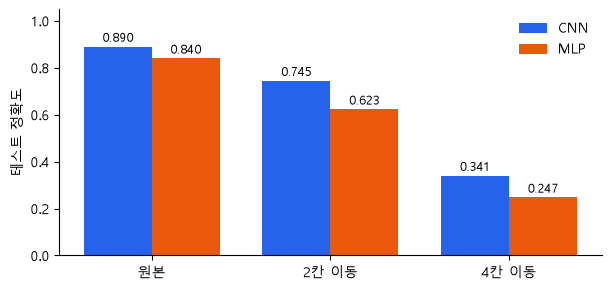

In [23]:
# 결과를 그림으로: 원본 · 2칸 · 4칸 옮긴 테스트 정확도
# 왜 · 이동 거리에 따른 정확도 차이를 한눈에 보기 위해
import matplotlib.pyplot as plt  # 그래프

plt.rcParams["font.family"] = "Malgun Gothic"              # 한글 글꼴 (Windows)
labels = ["원본", "2칸 이동", "4칸 이동"]                  # x축 이름
fig, ax = plt.subplots(figsize=(7, 3.2))                   # 그림 한 장
for k, (name, color) in enumerate([("CNN", "#2563eb"), ("MLP", "#ea580c")]):  # 모델마다 색
    xs = [i + (k - 0.5) * 0.38 for i in range(3)]          # 막대를 좌우로 나란히
    accs = results[name][1:]                               # [첫 loss, 원본, 2칸, 4칸] → 정확도 3개
    ax.bar(xs, accs, width=0.38, color=color, label=name)  # 막대 그리기
    for x, a in zip(xs, accs):                             # 막대마다
        ax.text(x, a + 0.02, f"{a:.3f}", ha="center", fontsize=9)  # 값 표시
ax.set_xticks(range(3), labels)                            # x축 눈금
ax.set_ylim(0, 1.05)                                       # 정확도 범위
ax.set_ylabel("테스트 정확도")                             # y축 이름
ax.legend(frameon=False)                                   # 범례
ax.spines[["top", "right"]].set_visible(False)             # 위 · 오른쪽 테두리 숨김
plt.show()                                                 # 출력

**결과** · 예측 정답은 CNN이 높음 (0.890 vs 0.840) — 하지만 4칸 옮긴 이미지에서는 CNN도 0.341로 크게 떨어짐 (MLP 0.247), 덜 무너질 뿐 위치에 무관해지지는 않음

- `Conv2d (1, 6, 28, 28) 60` — 6 × 1 × 3 × 3 + 6 = 60 · padding 1이라 28 유지
- `Conv2d (1, 16, 14, 14) 880` — 28 - 3 + 2 = 27, 27 ÷ 2 + 1 = 14.5 → 14 · 16 × 6 × 9 + 16 = 880
- `Conv2d (1, 16, 7, 7) 2,320` — 14 → 7 · 16 × 16 × 9 + 16 = 2320
- `ReLU (1, 16, 7, 7) 0` — ReLU는 모양도 파라미터도 바꾸지 않음
- `Flatten (1, 784) 0` — 16 × 7 × 7 = 784 → 이 길이가 Linear의 `in_features`
- `Linear (1, 10) 7,850` — 784 × 10 + 10 = 7850 · CNN 파라미터의 70.7%가 마지막 Linear
- `합계 11,110` / `합계 11,140` — CNN 전체 / MLP 전체 → 차이 30개 (0.3%)
- `Linear (1, 14) 10,990` — MLP 첫 층 784 × 14 + 14 = 10990
- `epoch 3 | 평균 loss 0.2929` — CNN 3 epoch 학습 손실 (MLP는 0.5685)
- `CNN | 2.3094 | 0.890 | 0.745 | 0.341` — 첫 loss 2.30 근처 → 연결 정상 · 원본 89.0%
- `MLP | 2.3448 | 0.840 | 0.623 | 0.247` — 첫 loss 정상 · 원본 84.0%

**CNN vs MLP 비교**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">항목</th><th style="text-align: left;">CNN</th><th style="text-align: left;">MLP</th><th style="text-align: left;">읽는 법</th></tr>
</thead>
<tbody>
<tr><td>파라미터</td><td>11,110</td><td>11,140</td><td>거의 같은 예산</td></tr>
<tr><td>파라미터가 몰린 곳</td><td>마지막 Linear 7,850 (70.7%)</td><td>첫 Linear 10,990 (98.7%)</td><td>MLP는 입력 784칸마다 가중치</td></tr>
<tr><td>3 epoch 학습 손실</td><td>0.2929</td><td>0.5685</td><td>같은 epoch에서 CNN이 더 빨리 내려감</td></tr>
<tr><td>원본 테스트 정확도</td><td><strong>0.890</strong></td><td>0.840</td><td>CNN이 5.0%p 높음</td></tr>
<tr><td>2칸 이동 정확도 (원본 대비)</td><td>0.745 (83.7% 유지)</td><td>0.623 (74.2% 유지)</td><td>CNN이 덜 무너짐</td></tr>
<tr><td>4칸 이동 정확도 (원본 대비)</td><td>0.341 (38.3% 유지)</td><td>0.247 (29.4% 유지)</td><td>둘 다 크게 무너짐 → CNN도 불변은 아님</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - CNN도 4칸 이동에서는 0.341로 크게 떨어짐
> - 합성곱은 "옮기면 같이 옮겨짐"(등변성)이고 마지막 Linear는 자리마다 가중치라 "옮겨도 같음"(불변성)은 보장 안 됨 · 한 번의 실행 · 한 seed
> - 부분집합 결과이므로 숫자보다 차이의 방향을 볼 것 (GPU에서 실행한 값 · CPU에서 다시 실행하면 CNN이 0.889 · 0.746 · 0.340처럼 소수 셋째 자리만 다름)

> ✅ **한 줄 정리** · 같은 파라미터 예산이면 창을 모든 자리에 다시 쓰는 CNN이 이미지에서 더 정확하고 위치 이동에도 덜 무너지지만, 위치에 완전히 무관해지지는 않는다.

**딥러닝 코드에서는**

- CNN-2에서 이 모델을 이어서 확장 · 풀링
- GAP으로 마지막 Linear를 면적에 안 묶이게 바꾸고(4칸 이동에 약했던 이유), `train()` · `eval()` · Dropout
- BatchNorm, 깊게 쌓는 VGG(3×3 반복)
- ResNet(shortcut)으로

### 8장 더 알아보기 · 방법별 차이

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>CNN (작은 3층)</td><td>같은 창을 모든 자리에 · 이웃 관계 사용 · 피처맵 격자 유지</td><td>이미지 · 위치가 제각각인 모양</td></tr>
<tr><td>MLP (펴서 넣기)</td><td>번호마다 가중치 · 이웃 관계 없음</td><td>정형 데이터 · CNN이 뽑은 특징 뒤 분류기</td></tr>
<tr><td>원본 정확도만 보기</td><td>학습과 같은 분포의 테스트만</td><td>빠른 비교</td></tr>
<tr><td>옮긴 테스트도 보기</td><td>위치 변화에 얼마나 버티는지</td><td>실제 사진처럼 물체 위치가 제각각일 때</td></tr>
<tr><td>stride 2 합성곱으로 줄이기 (이번 실습)</td><td>줄이는 방법까지 학습됨</td><td>풀링(MaxPool)과의 비교는 CNN-2</td></tr>
</tbody></table>

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>1. 이미지 축 읽기</td><td><code>(8, 1, 28, 28)</code>에서 <code>x[0, 0, 5]</code> → <code>(28,)</code>, 범위로 자르면 축 유지를 미리 말함</td><td>1-2</td></tr>
<tr><td>2. Dense의 한계</td><td>원래 자리를 배운 가중치가 옮긴 십자에 9점 → 2점, 합성곱은 9점 그대로</td><td>4-1 · 4-2</td></tr>
<tr><td>3. 합성곱 손계산</td><td>왼쪽 위 창 = 5, 3×3 피처맵 전체를 손으로 계산해 <code>F.conv2d</code>와 일치</td><td>5-1</td></tr>
<tr><td>4. 크기 · 파라미터 계산</td><td>28 · 3 · 2 · 0 → 13, <code>Conv2d(3, 16, 3)</code> → 448개를 손계산 후 코드로 검증</td><td>6-3 · 7-2</td></tr>
<tr><td>5. CNN vs MLP</td><td>같은 1.1만 개 예산에서 0.890 vs 0.840, 옮기면 둘 다 떨어지지만 CNN이 덜</td><td>8</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;"><code>A</code></td><td>값과 자리</td><td>같은 모양도 자리가 바뀌면 다른 숫자 표</td><td>모델이 받는 것은 <code>(1, 28, 28)</code> 숫자뿐</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>축 네 개</td><td><code>(N, C, H, W)</code> · 번호로 집으면 축이 사라짐</td><td><code>img.unsqueeze(0)</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>채널</td><td>장수가 아니라 층수 · 3채널 복사는 정보 그대로</td><td><code>img.repeat(3, 1, 1)</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>ToTensor</td><td>축 순서 · 자료형 · 0 ~ 1 세 가지</td><td><code>transforms.ToTensor()</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>데이터셋</td><td><code>len</code> · <code>[i]</code> · 꺼낼 때 변환</td><td><code>Subset(train, range(5000))</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;"><code>A</code></td><td>DataLoader</td><td>마지막 배치는 작음 · <code>shape[0]</code>으로 읽기</td><td><code>DataLoader(..., shuffle=True)</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>펴기</td><td>값은 그대로 · 이웃은 사라짐 · 배치 유지</td><td><code>nn.Flatten()</code></td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>Linear 크기</td><td>weight <code>(out, in)</code> · 입력 면적에 비례</td><td><code>in_features</code> = 펼친 길이</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>첫 loss</td><td>ln(클래스 수) 근처 · 같은 배치 반복으로 연결 확인</td><td>10종이면 2.30</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>Dense의 한계</td><td>번호마다 가중치 → 옮기면 다시 배움</td><td>이미지에는 Conv</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;"><code>A</code></td><td>같은 창 옮겨 쓰기</td><td>옮기면 같이 옮겨짐 · 파라미터는 면적과 무관</td><td><code>nn.Conv2d(1, 8, 3)</code> = 80개</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>합성곱 한 칸</td><td>같은 자리끼리 곱해 전부 더함</td><td><code>F.conv2d</code> = 손계산</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>커널 값</td><td>큰 값 = 닮은 무늬 · PyTorch는 뒤집지 않음</td><td>커널은 학습으로 정해짐</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>커널 크기</td><td>키우면 파라미터 · 계산 ↑, 출력 ↓</td><td>기본 3×3</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>stride</td><td>2면 출력 약 절반 · 계산 약 1/4</td><td><code>stride=2</code>로 줄이기</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>padding</td><td>3×3엔 padding 1로 크기 유지</td><td><code>padding=1</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;"><code>A</code></td><td>출력 크기 공식</td><td><code>(W - K + 2P) // S + 1</code> · 축마다 · 내림</td><td>층마다 H · W 적어 내려가기</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>다채널 필터</td><td>층마다 slice → 더하고 bias → 출력 1장</td><td>필터 하나에 in × k × k개</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>in / out channels</td><td>in은 데이터 · out은 내가 · <code>(out, in, kH, kW)</code></td><td>앞 층 out = 뒤 층 in</td></tr>
<tr><td style="text-align: center;"><code>A</code></td><td>종합</td><td>같은 예산에서 CNN이 더 정확 · 이동에도 덜 무너짐 (불변은 아님)</td><td>CNN-2에서 풀링 · GAP · ResNet</td></tr>
</tbody></table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-1** · 같은 십자를 한 칸 옮기면 숫자 표로는 왜 다른 이미지인가?
- **1-2** · `(N, C, H, W)`의 각 축은? `(3, 28, 28)`은 몇 장인가?
- **1-3** · 흑백을 3채널로 복사하면 개수와 정보는 각각 어떻게 되나? `repeat`와 `expand`의 차이는?
- **1-4** · `ToTensor`가 바꾸는 세 가지는?
- **2-1** · 데이터셋이 약속하는 두 가지와, 변환이 일어나는 때는?
- **2-2** · 60,000장을 64장씩 나누면 배치 수와 마지막 배치 크기는?
- **3-1** · `nn.Flatten()`과 `torch.flatten(x)`의 차이는? 펴면 무엇이 사라지나?
- **3-2** · `nn.Linear(784, 200)`의 weight 모양과 파라미터 수는?
- **3-3** · 10종 분류에서 첫 loss가 2.3 근처여야 하는 이유는?
- **4-1** · 같은 모양을 옮기면 Dense는 왜 다시 배워야 하나?
- **4-2** · `nn.Linear`와 `nn.Conv2d`의 파라미터는 입력 크기와 어떤 관계인가?
- **5-1** · 합성곱 출력 한 칸은 어떻게 계산하나?
- **5-3** · 커널을 3 → 5로 키우면 확실히 바뀌는 것은?
- **6-1** · 28×28 · 3×3 · stride 2 · padding 0의 출력과 계산량 변화는?
- **6-2** · padding 0과 1의 차이와, 3×3에서 크기를 유지하는 조건은?
- **6-3** · 출력 크기 공식과 반드시 같이 기억할 세 가지는?
- **7-1** · 3채널 입력에서 필터 하나는 어떻게 출력 한 장을 만드나?
- **7-2** · `in_channels` · `out_channels`는 누가 정하고, weight 모양과 파라미터 공식은?
- **8** · 같은 크기의 CNN과 MLP는 원본 · 옮긴 이미지에서 어떻게 달랐나?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**8** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. `(16, 3, 64, 64)` 배치에서 첫 장의 초록(G) 채널만 꺼내 shape 출력
2. 입력 32 · 커널 5 · padding 2일 때 stride 1과 stride 2의 출력 크기를 공식으로 계산
3. `nn.Conv2d(3, 32, 5)`의 파라미터 수를 코드로 세기 (손계산과 비교)
4. `(8, 16, 7, 7)` 피처맵을 배치 축은 남기고 펴서, shape와 다음 Linear의 `in_features` 출력
5. 모두 1인 5×5 입력에 모두 1인 3×3 커널을 `F.conv2d`로 적용한 결과의 shape와 값

In [24]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 6-3의 공식으로 **입력 64 · 커널 7 · stride 2 · padding 3**의 출력 크기를 먼저 손으로 구한 뒤 `nn.Conv2d`로 확인
2. 8장 CNN의 첫 층을 `nn.Conv2d(1, 8, 5, padding=2)`로 바꾸면 그 층의 파라미터 수와 출력 shape는? (뒤 층의 `in_channels`도 맞춰야 함)
3. 4-2의 십자를 **두 칸** 옮기면 Dense 점수와 합성곱 최고 점수 · 위치는 각각 어떻게 될까? 예측 → 실행

In [25]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-1** · 컴퓨터는 값과 자리를 함께 받으므로, 값 9개는 같아도 49자리 중 14자리가 달라져 다른 입력이 됨
- **1-2** · 장수 · 채널(한 자리에 값이 몇 개) · 세로 · 가로. `(3, 28, 28)`은 컬러 1장 (3장이면 축 4개)
- **1-3** · 개수는 3배, 정보는 그대로. `repeat`는 복사, `expand`는 메모리 공유
- **1-4** · 축 순서 (H, W, C) → (C, H, W) · 자료형 uint8 → float32 · 범위 0 ~ 255 → 0 ~ 1
- **2-1** · 전체 개수 `len` · 번호로 하나 꺼내기 `[i]`. 변환은 꺼낼 때마다 그 한 장에만
- **2-2** · 938개 (`drop_last=False`), 마지막 배치 32장 (64 × 937 + 32)
- **3-1** · `nn.Flatten()`은 배치 축을 남기고, `torch.flatten(x)`는 전부 한 줄. 값은 그대로, 이웃 관계가 사라짐
- **3-2** · `(200, 784)` · 784 × 200 + 200 = 157000
- **3-3** · 학습 전에는 10칸 확률이 약 0.1씩이라 -ln(0.1) ≈ 2.3. 크게 벗어나면 연결 오류
- **4-1** · 번호마다 가중치를 따로 가져서, 위치가 바뀌면 다른 번호 · 다른 가중치가 받기 때문
- **4-2** · Linear는 입력 면적에 비례해 커지고, Conv2d는 입력 크기와 무관 (필터 수 × 창 크기 + bias)
- **5-1** · 창 안 값과 커널을 같은 자리끼리 곱해 모두 더함 (+ bias)
- **5-3** · 파라미터 · 계산량 증가, 출력 크기 감소. 더 좋은 특징은 보장 안 됨
- **6-1** · 13×13 (13.5 → 내림). 2차원이라 계산량은 약 1/4
- **6-2** · padding 0은 출력이 K - 1칸 줄고, padding 1은 3×3 · stride 1에서 크기 유지
- **6-3** · `(W - K + 2P) // S + 1` · 축마다 따로 · 양쪽이라 2P · 내림
- **7-1** · 층마다 slice를 얹어 부분합을 구한 뒤 모두 더하고 bias 하나를 붙임
- **7-2** · in은 데이터(앞 층)가, out은 내가 정함. `(out, in, kH, kW)` · `out × (in × kH × kW) + out`

- **8** · 파라미터 약 1.1만 개로 같을 때 CNN 0.890 · MLP 0.840, 2칸 이동 0.745 · 0.623, 4칸 이동은 둘 다 크게 떨어짐

#### 코드 문제 답

```python
# 1. 번호로 집은 축은 사라짐 → (H, W)
x = torch.zeros(16, 3, 64, 64)
print(tuple(x[0, 1].shape))  # (64, 64)

# 2. (W - K + 2P) // S + 1
print((32 - 5 + 2 * 2) // 1 + 1, (32 - 5 + 2 * 2) // 2 + 1)  # 32 16

# 3. out × (in × k × k) + out = 32 × 75 + 32
conv = nn.Conv2d(3, 32, 5)
print(sum(p.numel() for p in conv.parameters()))  # 2432

# 4. 배치 축을 남기고 펴기 → in_features = 16 × 7 × 7
flat = torch.flatten(torch.zeros(8, 16, 7, 7), 1)
print(tuple(flat.shape), flat.shape[1])  # (8, 784) 784

# 5. 창 9칸이 모두 1 × 1 → 9칸 모두 9 · 5 - 3 + 1 = 3
out = F.conv2d(torch.ones(1, 1, 5, 5), torch.ones(1, 1, 3, 3))
print(tuple(out.shape), out.unique().tolist())  # (1, 1, 3, 3) [9.0]
```

#### 변형 문제 답

*문제 → 답*

- **1** · 64 - 7 + 6 = 63, 63 ÷ 2 + 1 = 32.5 → 32
- **2** · 8 × (1 × 25) + 8 = 208개 · `(8, 28, 28)` (padding 2라 크기 유지) · 다음 층은 `nn.Conv2d(8, 16, ...)`
- **3** · Dense는 겹치는 자리가 줄어 점수가 더 낮아짐 · 합성곱은 최고 점수 9 그대로, 위치만 두 칸 이동

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>(예) 28 · 3 · 2 · 0을 14로 답함</td><td>2로 나누기만 하고 공식을 안 씀</td><td><code>(W - K + 2P) // S + 1</code>, 내림</td><td>공식에 넣고 내림까지 했나?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. 이미지에 MLP 대신 CNN을 쓰는 이유는?**
> - MLP는 이미지를 펴서 넣기 때문에 픽셀 번호마다 가중치를 따로 가져, 같은 모양이 한 칸만 옮겨도 다른 가중치가 받아 다시 배워야 하고 입력 크기에 비례해 파라미터가 폭증합니다.
> - CNN은 작은 커널 한 벌을 모든 위치에 다시 쓰므로 이웃 픽셀 관계를 이용하고, 옮긴 모양에도 같은 반응을 옮긴 자리에서 내며, 파라미터 수가 입력 크기와 무관합니다.
> - 다만 완전한 위치 불변성을 보장하지는 않습니다.

**Q2. 합성곱 출력 크기는 어떻게 계산하나요?**
> - 입력 W, 커널 K, padding P, stride S일 때 (W − K + 2P) / S + 1을 축마다 따로 계산하고, 나누어떨어지지 않으면 내립니다.
> - 창의 왼쪽 끝이 놓일 수 있는 자리 수를 세는 것이라 남는 칸은 버려집니다.
> - 예를 들어 28×28에 3×3, stride 2, padding 1이면 14가 됩니다.

**Q3. Conv2d의 weight 모양과 파라미터 수는?**
> - weight는 (out_channels, in_channels, kH, kW)이고 bias는 출력 채널마다 하나라서 파라미터는 out × (in × kH × kW) + out입니다.
> - 필터 하나가 입력 채널 수만큼 slice를 갖고, 층마다 계산한 값을 모두 더한 뒤 bias를 더해 출력 채널 한 장을 만들기 때문입니다.
> - 이미지 면적은 공식에 들어가지 않습니다.

**Q4. padding과 stride는 각각 언제 쓰나요?**
> - padding은 바깥에 0을 붙여 가장자리 정보가 덜 반영되는 문제를 줄이고 출력 크기를 유지할 때 씁니다.
> - 3×3 커널에 padding 1, stride 1이면 크기가 그대로입니다.
> - stride는 창을 옮기는 폭이라 2로 두면 가로와 세로가 각각 절반이 되어 계산량이 약 1/4로 줄고, 특징 맵을 줄이는 단계에서 씁니다.

**Q5. 학습 시작 전 첫 loss가 2.3인지 확인하는 이유는?**
> - 10개 클래스 분류에서 아무것도 배우지 않은 모델은 각 클래스 확률이 약 0.1이라 cross entropy가 −ln(0.1) ≈ 2.3이 됩니다.
> - 첫 loss가 이 근처가 아니면 출력 차원, 정답 형식, softmax 중복 같은 연결 오류를 의심할 수 있어 가장 싼 점검입니다.
> - 이어서 한 배치를 반복 학습해 loss가 내려가는지도 확인합니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>torch.zeros()</code> · <code>!=</code> · <code>.sum()</code></td><td>torch · 텐서 연산</td><td>격자 만들기 · 자리별 비교 · 개수 세기</td><td>1-1 <code>cross = torch.zeros(7, 7)</code></td></tr>
<tr><td><code>torch.stack()</code> · <code>x[0, 0]</code> · <code>x[:, :, a:b]</code></td><td>torch · 인덱싱</td><td>배치 만들기 · 축 벗기기 · 범위 자르기</td><td>1-2 <code>x = torch.stack([train_full[i][0] for i in range(8…</code></td></tr>
<tr><td><code>.repeat()</code> · <code>.expand()</code> · <code>.data_ptr()</code></td><td>텐서 메서드</td><td>채널 복사 · 복사 없이 늘리기 · 메모리 주소</td><td>1-3 <code>rgb_copy = gray.repeat(3, 1, 1)</code></td></tr>
<tr><td><code>transforms.ToTensor()</code></td><td>torchvision.transforms</td><td>(H, W, C) uint8 → (C, H, W) float 0 ~ 1</td><td>0 · 1-4 <code>t = to_tensor(photo)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>.permute(2, 0, 1)</code> · <code>torch.from_numpy()</code></td><td>텐서 메서드 · torch</td><td>축 순서 바꾸기 · NumPy → 텐서</td><td>1-4 <code>manual = torch.from_numpy(photo).permute(2, 0, 1).…</code></td></tr>
<tr><td><code>datasets.MNIST(root, train, download, transform)</code></td><td>torchvision.datasets</td><td>MNIST 내려받기 · 데이터셋</td><td>2-1 <code>counted = datasets.MNIST("data", train=True, trans…</code></td></tr>
<tr><td><code>len(dataset)</code> · <code>dataset[i]</code></td><td>Dataset 약속</td><td>전체 개수 · i번 (이미지, 정답)</td><td>2-1 <code>print("개수:", len(train_full))</code></td></tr>
<tr><td><code>Subset(dataset, 번호)</code></td><td>torch.utils.data</td><td>일부만 쓰기 (원본 공유)</td><td>2-1 <code>small = Subset(train_full, range(2000))</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>DataLoader(batch_size, shuffle, drop_last, generator)</code></td><td>torch.utils.data</td><td>배치 공급 · 섞기 · 마지막 버리기 · 순서 고정</td><td>2-2 <code>keep = DataLoader(train_full, batch_size=64, drop_…</code></td></tr>
<tr><td><code>divmod(a, b)</code></td><td>Python 내장 함수</td><td>몫 · 나머지</td><td>2-2 <code>q, r = divmod(len(train_full), 64)</code></td></tr>
<tr><td><code>nn.Flatten()</code> · <code>torch.flatten(x, 1)</code></td><td>torch.nn · torch</td><td>배치 축을 남기고 펴기</td><td>3-1 <code>print("nn.Flatten()       :", tuple(nn.Flatten()(x…</code></td></tr>
<tr><td><code>nn.Linear(in, out)</code> · <code>.weight</code> · <code>.bias</code></td><td>torch.nn</td><td>곱셈표 한 장 · (out, in) · (out,)</td><td>3-2 <code>fc = nn.Linear(784, 200)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>nn.Sequential()</code> · <code>.named_children()</code></td><td>torch.nn</td><td>층을 순서대로 묶기 · 층 이름과 함께 꺼내기</td><td>3-2 <code>mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 2…</code></td></tr>
<tr><td><code>.parameters()</code> · <code>.numel()</code></td><td>nn.Module · 텐서 메서드</td><td>파라미터 수 세기</td><td>3-2 <code>total = sum(p.numel() for p in mlp.parameters())</code></td></tr>
<tr><td><code>.softmax(dim=1)</code> · <code>F.cross_entropy()</code></td><td>텐서 메서드 · torch.nn.functional</td><td>확률로 · 로짓 + 정답 번호 → 손실</td><td>3-3 <code>probs = logits.softmax(dim=1)</code></td></tr>
<tr><td><code>torch.optim.Adam()</code> · <code>zero_grad</code> · <code>backward</code> · <code>step</code></td><td>torch.optim · autograd</td><td>같은 배치 반복 점검 (자세히는 딥러닝기초-2)</td><td>3-3 <code>opt = torch.optim.Adam(mlp.parameters(), lr=1e-3)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>.flatten().nonzero()</code></td><td>텐서 메서드</td><td>편 뒤 0이 아닌 번호</td><td>4-1 <code>idx_a = cross.flatten().nonzero().flatten().tolist()</code></td></tr>
<tr><td><code>torch.roll(x, shifts, dims)</code></td><td>torch</td><td>이미지를 몇 칸 옮기기 (밀려난 칸은 반대편으로)</td><td>4-1 <code>shifted = torch.roll(img, shifts=1, dims=2)</code></td></tr>
<tr><td><code>F.cosine_similarity()</code></td><td>torch.nn.functional</td><td>두 벡터 방향 비교 (1 = 같음)</td><td>4-1 <code>print("코사인 유사도:", round(F.cosine_similarity(a, b, …</code></td></tr>
<tr><td><code>F.conv2d(x, kernel)</code> · <code>nn.Conv2d(in, out, k)</code></td><td>torch.nn.functional · torch.nn</td><td>같은 창을 모든 자리에 · 층</td><td>4-2 <code>fmap_a = F.conv2d(cross.view(1, 1, 7, 7), k_cross)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>torch.allclose()</code></td><td>torch</td><td>두 텐서가 거의 같은가</td><td>4-2 <code>torch.allclose(fb[..., 1:], fa[..., :-1])</code></td></tr>
<tr><td><code>(patch * kernel).sum()</code></td><td>텐서 연산</td><td>같은 자리끼리 곱해 전부 더함 = 출력 한 칸</td><td>5-1 <code>(x5[0, 0, i:i + 3, j:j + 3] * k3[0, 0]).sum()</code></td></tr>
<tr><td><code>F.conv2d(x, w)</code></td><td>torch.nn.functional</td><td>직접 정한 커널로 합성곱</td><td>5-1 <code>auto = F.conv2d(x5, k3)</code></td></tr>
<tr><td><code>.transpose(2, 3).contiguous()</code></td><td>텐서 메서드</td><td>커널 가로 · 세로 바꾸기</td><td>5-2 <code>horizontal = vertical.transpose(2, 3).contiguous()</code></td></tr>
<tr><td><code>torch.flip(k, dims=[2, 3])</code></td><td>torch</td><td>커널 반 바퀴 돌리기 (수학의 합성곱)</td><td>5-2 <code>flipped = torch.flip(k3, dims=[2, 3])</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>kernel_size</code></td><td>nn.Conv2d 인자</td><td>창 크기 (보통 3)</td><td>5-3 <code>layer = nn.Conv2d(1, 8, kernel_size=k)</code></td></tr>
<tr><td><code>stride=1</code> · <code>stride=2</code></td><td>nn.Conv2d 인자</td><td>창을 옮기는 폭</td><td>6-1 <code>nn.Conv2d(1, 1, 3, stride=s)(x28)</code></td></tr>
<tr><td><code>padding=1</code> · <code>padding="same"</code></td><td>nn.Conv2d 인자</td><td>바깥에 0 채우기 · 크기 유지 자동</td><td>6-2 <code>F.conv2d(x5, k3, padding=p)</code> · <code>nn.Conv2d(1, 4, 3, padding="same")</code></td></tr>
<tr><td><code>(w - k + 2 * p) // s + 1</code></td><td>Python 연산 (<code>//</code> 내림)</td><td>출력 크기 공식</td><td>6-3 <code>return (w - k + 2 * p) // s + 1</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>kernel_size=(3, 5)</code> · <code>stride=(2, 1)</code></td><td>nn.Conv2d 인자 (튜플)</td><td>(세로, 가로) 따로</td><td>6-3 <code>nn.Conv2d(1, 1, (3, 5), stride=(2, 1), padding=(1, 0))</code></td></tr>
<tr><td><code>ValueError</code></td><td>Python 예외</td><td>stride 2 + <code>padding="same"</code></td><td>6-2 <code>except ValueError as e:</code></td></tr>
<tr><td><code>F.conv2d(x, w, b)</code></td><td>torch.nn.functional</td><td>다채널 입력 · 필터 · bias</td><td>7-1 <code>out1 = F.conv2d(rgb.unsqueeze(0), f_w, f_b)</code></td></tr>
<tr><td><code>nn.Conv2d(in_channels, out_channels, kernel_size)</code></td><td>torch.nn</td><td>입력 층 수 · 필터 수 · 창 크기</td><td>7-2 <code>conv34 = nn.Conv2d(in_channels=3, out_channels=4, …</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>conv.weight.shape</code> · <code>conv.bias.shape</code></td><td>nn.Conv2d 속성</td><td><code>(out, in, kH, kW)</code> · <code>(out,)</code></td><td>7-2 <code>conv34.weight.shape</code> · <code>conv34.bias.shape</code></td></tr>
<tr><td><code>groups</code></td><td>nn.Conv2d 인자</td><td>기본 1 = 모든 필터가 모든 입력 층을 봄</td><td>7-2 <code>print("groups=1:", tuple(nn.Conv2d(3, 6, 3).weight…</code></td></tr>
<tr><td><code>RuntimeError</code> (channels)</td><td>Python 예외</td><td>in_channels와 입력 채널이 다를 때</td><td>7-2 <code>except RuntimeError as e:</code></td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td>축 개수부터 세고 <code>(N, C, H, W)</code>로 읽기</td><td><code>(3, 28, 28)</code>을 3장으로 읽기</td></tr>
<tr><td>배치 크기는 <code>images.shape[0]</code></td><td>숫자 64를 코드에 박아 두기</td></tr>
<tr><td>배치에는 <code>nn.Flatten()</code> · <code>flatten(x, 1)</code></td><td>배치에 <code>torch.flatten(x)</code></td></tr>
<tr><td>학습 전에 첫 loss ≈ ln(클래스 수) 확인</td><td>모델 끝에 softmax를 넣고 <code>cross_entropy</code></td></tr>
<tr><td>층마다 출력 크기 공식으로 H · W 계산 → 더미 입력으로 검증</td><td><code>Linear</code> 입력 길이를 어림으로 적기</td></tr>
<tr><td>3×3에는 <code>padding=1</code></td><td>stride 2에 <code>padding="same"</code></td></tr>
<tr><td><code>in_channels</code>를 앞 층 <code>out_channels</code>와 맞추기</td><td>흑백 데이터에 <code>in_channels=3</code></td></tr>
<tr><td>성능은 처음 보는 테스트로 · 옮긴 이미지로도</td><td>같은 배치 loss 감소를 실력으로 착각</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td><code>(C, H, W)</code> vs <code>(N, C, H, W)</code></td><td>한 장 vs 배치</td><td>축 개수부터 세기</td></tr>
<tr><td>채널 vs 장수</td><td>같은 자리의 층 수 vs 이미지 개수</td><td><code>(3, 28, 28)</code>은 컬러 1장</td></tr>
<tr><td><code>repeat</code> vs <code>expand</code></td><td>복사 vs 메모리 공유</td><td>수정할 거면 <code>repeat</code></td></tr>
<tr><td><code>(H, W, C)</code> vs <code>(C, H, W)</code></td><td>사진 · 그림 vs PyTorch 층</td><td><code>ToTensor</code>가 바꿔 줌</td></tr>
<tr><td><code>ToTensor</code> vs <code>Normalize</code></td><td>축 · 자료형 · 0 ~ 1 vs 평균 · 표준편차로 맞춤</td><td>ToTensor 다음 Normalize</td></tr>
<tr><td><code>drop_last=False</code> vs <code>True</code></td><td>마지막 작은 배치 사용 vs 버림</td><td>보통 False · 배치 크기는 <code>shape[0]</code></td></tr>
<tr><td><code>nn.Flatten()</code> vs <code>torch.flatten(x)</code></td><td>배치 유지 vs 전부 한 줄</td><td>배치에는 <code>nn.Flatten()</code> · <code>flatten(x, 1)</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td><code>Linear(in, out)</code> vs <code>weight</code><code>(out, in)</code></td><td>쓰는 순서 vs 저장 모양</td><td>순서가 반대</td></tr>
<tr><td><code>nn.Linear</code> vs <code>nn.Conv2d</code></td><td>모든 칸 · 번호마다 vs 작은 창 · 공유</td><td>특징은 Conv, 마지막 분류는 Linear</td></tr>
<tr><td>등변성 vs 불변성</td><td>옮기면 같이 옮겨짐 vs 옮겨도 같음</td><td>Conv는 등변성 · 불변성은 보장 안 됨</td></tr>
<tr><td><code>F.conv2d</code> vs <code>nn.Conv2d</code></td><td>가중치를 넘김 vs 안에 갖고 학습</td><td>모델은 <code>nn.Conv2d</code></td></tr>
<tr><td>cross-correlation vs 합성곱</td><td>커널 그대로 vs 뒤집어서</td><td>PyTorch는 그대로</td></tr>
<tr><td>kernel 3 vs 5</td><td>9칸 vs 25칸 · 가중치 약 2.8배</td><td>기본은 3</td></tr>
<tr><td>stride 1 vs 2</td><td>모든 자리 vs 건너뜀 · 계산 약 1/4</td><td>크기를 줄일 때 2</td></tr>
<tr><td>padding 0 vs 1</td><td>출력 줄어듦 vs 3×3에서 유지</td><td>3×3에는 padding 1</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td><code>in_channels</code> vs <code>out_channels</code></td><td>데이터가 정함 vs 내가 정함</td><td>앞 층 out = 뒤 층 in</td></tr>
<tr><td>slice vs 필터</td><td>한 장 vs slice 묶음 + bias</td><td>필터 수 = 출력 채널 수</td></tr>
<tr><td>첫 loss 점검 vs 테스트 정확도</td><td>연결 확인 vs 실력 확인</td><td>점검 먼저, 성능은 테스트로</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td><td>15분</td></tr>
<tr><td>3일 뒤</td><td>변형 문제 3개를 새로 풀기 · 6-3 손계산표를 가리고 다시 채우기</td><td>20분</td></tr>
<tr><td>7일 뒤</td><td>8장 CNN을 직접 다시 짜서 층별 shape를 먼저 손으로 적고 실행</td><td>30분</td></tr>
<tr><td>14일 뒤</td><td>오답 노트에 남은 문제만 다시 풀기 · CNN-2 시작 전 1 · 6 · 7장 ✅ 줄만 읽기</td><td>15분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- CNN DAY01 슬라이드(267쪽, 챕터 1 ~ 8)를 중복 없이 7개 대단원
- 19개 섹션으로 재구성하고, 8장 종합 실습(작은 CNN vs 파라미터가 거의 같은 MLP를 MNIST로 학습)으로 연결.
- 실습 노트북이 없어서 슬라이드 속 코드 조각을 모아 실행되는 코드로 다시 만들고, 결과는 모두 실행으로 확인함.
- 데이터는 슬라이드의 FashionMNIST 대신 torchvision MNIST(손글씨 숫자 · 모양은 같은 `(1, 28, 28)`).
- 딥러닝기초-2와 겹치는 Dataset · DataLoader · 학습 루프 · 손실 계약
- 옵티마이저는 이미지에서 확인할 점만 다루고 참조로 대체.
- 💡 쉬운 설명 일부는 코드잇 CNN PDF를 보조 자료로 사용.

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 예측 정답 · 결과 해설 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 = 이 단계에서 하는 일, 코드 옆 = 실행 흐름 · 문법 구조

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">DAY01 쪽</th><th style="text-align: left;">원본 챕터</th><th style="text-align: left;">슬라이드 코드 조각 (쪽)</th><th style="text-align: left;">섹션</th></tr>
</thead>
<tbody>
<tr><td>1 ~ 21</td><td>1 이미지 텐서 (값 · 자리 · 축 · 채널)</td><td>14 · 16</td><td>1-1 · 1-2 · 1-3</td></tr>
<tr><td>22 ~ 33</td><td>1 데이터 공급 (FashionMNIST · ToTensor · 배치)</td><td>25 · 27 · 32</td><td>2-1 · 1-4 · 2-2 (FashionMNIST → <strong>MNIST</strong>로 바꿈)</td></tr>
<tr><td>35 ~ 62</td><td>2 일렬로 편 픽셀 판별 모델</td><td>43 · 46 · 47 · 55</td><td>3-1 · 3-2 (Sequential과 클래스 표기는 딥러닝기초-2 참조)</td></tr>
<tr><td>63 ~ 81</td><td>3 앞 절반 · 벌점(softmax · CrossEntropy · BCE)</td><td>73 · 76 · 78</td><td>3-3 <strong>첫 loss 점검만</strong> (손실 계약 · BCE 계열은 딥러닝기초-2 참조)</td></tr>
<tr><td>82 ~ 97</td><td>3 뒤 절반 · backward · step · 옵티마이저</td><td>83 · 84 · 86 · 87</td><td>3-3 같은 배치 반복 점검 (옵티마이저 비교는 딥러닝기초-2 참조)</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">DAY01 쪽</th><th style="text-align: left;">원본 챕터</th><th style="text-align: left;">슬라이드 코드 조각 (쪽)</th><th style="text-align: left;">섹션</th></tr>
</thead>
<tbody>
<tr><td>98 ~ 123</td><td>4 학습 · 검증 루프 · 과적합 · 모드 · 장치</td><td>99 · 109 · 110 · 121 · 122 · 123</td><td>0 장치 · 8 짧은 학습 루프 (데이터 분할은 머신러닝-1, <code>train()</code> · <code>eval()</code>은 CNN-2)</td></tr>
<tr><td>124 ~ 155</td><td>5 만든 모델을 부순다 (Dense의 한계)</td><td>131 · 133 · 145</td><td>4-1 · 4-2</td></tr>
<tr><td>156 ~ 193</td><td>6 창 안에서 벌어지는 일</td><td>173 · 176 · 177 · 183 · 184 · 187 · 190</td><td>5-1 · 5-2 · 5-3</td></tr>
<tr><td>194 ~ 229</td><td>7 창을 어떻게 움직이는가</td><td>199 · 207 · 215 · 217 · 218 · 220 · 224 · 227</td><td>6-1 · 6-2 · 6-3</td></tr>
<tr><td>230 ~ 267</td><td>8 다채널 입력과 여러 필터</td><td>244 · 254 · 255 · 256 · 257 · 259 · 263 · 265</td><td>7-1 · 7-2</td></tr>
<tr><td>코드잇 CNN PDF</td><td>보조 자료 (FCN 한계 · 패딩 종류 · 출력 크기 예제)</td><td>—</td><td>💡 설명 · 6-3 손계산표 예제 2개</td></tr>
</tbody></table>

### 전체 지도

#### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">순서</th><th style="text-align: left;">배우는 이유</th><th style="text-align: left;">대단원</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;">1</td><td>이미지는 값 + 자리이고, PyTorch에서는 <code>(N, C, H, W)</code> 텐서다</td><td>이미지 텐서</td></tr>
<tr><td style="text-align: center;">2</td><td>그 텐서를 6만 장 단위로 모델에 공급해야 한다</td><td>데이터 공급</td></tr>
<tr><td style="text-align: center;">3</td><td>가장 단순한 모델(펴서 Linear)을 만들고 학습 연결을 점검한다</td><td>펴서 분류하기와 첫 점검</td></tr>
<tr><td style="text-align: center;">4</td><td>그 모델은 위치가 바뀐 모양을 다시 배워야 하고 입력이 크면 폭증한다</td><td>Dense의 위치 문제</td></tr>
<tr><td style="text-align: center;">5</td><td>그래서 작은 창 하나를 옮겨 쓰는 계산(합성곱)을 손으로 확인한다</td><td>합성곱 계산</td></tr>
<tr><td style="text-align: center;">6</td><td>창을 옮기는 규칙을 정하고 층마다 H · W를 계산한다</td><td>출력 크기</td></tr>
<tr><td style="text-align: center;">7</td><td>층이 여러 장이면 필터 · weight가 어떻게 생기는지 정하고 C를 계산한다</td><td>채널 · 필터 · weight</td></tr>
<tr><td style="text-align: center;">8</td><td>1 ~ 7을 써서 작은 CNN을 만들고 같은 크기의 MLP와 비교한다</td><td>종합 실습</td></tr>
</tbody></table>

#### 합성곱 모델 한 바퀴 · 이 권 전체가 설명하는 흐름

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">순서</th><th style="text-align: left;">코드</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">섹션</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;">1</td><td><code>images</code><code>(N, 1, 28, 28)</code></td><td>이미지 배치 = 값 + 자리</td><td>1-1 · 1-2 · 2-2</td></tr>
<tr><td style="text-align: center;">2</td><td><code>nn.Conv2d(1, 6, 3, padding=1)</code></td><td>3×3 창 6벌을 모든 자리에 → <code>(N, 6, 28, 28)</code></td><td>4-2 · 5-1 · 6-2 · 7-2</td></tr>
<tr><td style="text-align: center;">3</td><td><code>nn.Conv2d(6, 16, 3, stride=2, padding=1)</code></td><td>건너뛰며 줄이기 28 → 14 → 7</td><td>6-1 · 6-3 · 7-1</td></tr>
<tr><td style="text-align: center;">4</td><td><code>nn.Flatten()</code></td><td><code>(N, 16 * 7 * 7)</code> = <code>(N, 784)</code></td><td>3-1</td></tr>
<tr><td style="text-align: center;">5</td><td><code>nn.Linear(784, 10)</code></td><td>클래스 점수 10개 (로짓)</td><td>3-2</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: center;">순서</th><th style="text-align: left;">코드</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">섹션</th></tr>
</thead>
<tbody>
<tr><td style="text-align: center;">6</td><td><code>F.cross_entropy(logits, labels)</code></td><td>첫 loss ≈ 2.3 점검 → 학습</td><td>3-3 · 8</td></tr>
</tbody></table>

#### ML/DL 공통 파이프라인 · 각 대단원이 쓰이는 곳

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰이는 장</th></tr>
</thead>
<tbody>
<tr><td>① 데이터 준비</td><td>MNIST 내려받기 · 부분집합</td><td>0장 · 2장 · <strong>8장</strong></td></tr>
<tr><td>② 불러오기</td><td>Dataset → DataLoader 배치</td><td>2장 · <strong>8장</strong></td></tr>
<tr><td>③ 전처리</td><td>ToTensor · 채널 맞추기</td><td>1장</td></tr>
<tr><td>④ 모델</td><td>펴기 · Linear · 합성곱 · stride · padding · 채널</td><td>3장 ~ 7장 · <strong>8장</strong></td></tr>
<tr><td>⑤ 학습</td><td>첫 loss 점검 · 짧은 학습</td><td>3장 · <strong>8장</strong></td></tr>
<tr><td>⑥ 평가</td><td>테스트 정확도 · 이동한 이미지 정확도</td><td><strong>8장</strong></td></tr>
<tr><td>⑦ 저장 · 기록</td><td>층별 shape · 파라미터 기록</td><td>6장 · 7장 · <strong>8장</strong> (모델 저장은 딥러닝기초-2)</td></tr>
</tbody></table>

**굵은 8장** · 종합 실습이 ① ② ④ ⑤ ⑥ ⑦ 을 한 번에 연결

### 전체 코드

1 ~ 8장 핵심 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며(GPU가 없으면 cpu, MNIST가 없으면 내려받음), 각 출력 앞 `[번호]`가 섹션.

**실행 흐름**

1. 전체 코드가 쓰는 도구 · 데이터 준비

In [26]:
# ---------- 0. 준비
# 왜 · 이 셀들만 위에서부터 실행해도 전체가 동작하도록 도구 · 데이터를 먼저 준비하기 위해
import math  # 첫 loss 기댓값 ln(10)

import numpy as np                               # 사진 배열 흉내
import torch                                     # 텐서 · 자동 미분
import torch.nn as nn                            # 층
import torch.nn.functional as F                  # conv2d · cross_entropy
from torch.utils.data import DataLoader, Subset  # 배치 · 부분집합
from torchvision import datasets, transforms     # MNIST · ToTensor

torch.manual_seed(0)                                            # 난수 기준값 고정 → 같은 환경에서 같은 결과
torch.backends.cudnn.deterministic = True                       # 같은 GPU · 같은 버전에서 합성곱도 매번 같은 값
torch.backends.cudnn.benchmark = False                          # 실행마다 계산 방법이 바뀌지 않게
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 없으면 cpu
to_tensor = transforms.ToTensor()                               # 사진 → 텐서 변환기 (1-4)
train_full = datasets.MNIST("data", train=True, download=True,  # 학습용 6만 장
                            transform=to_tensor)
test_full = datasets.MNIST("data", train=False, download=True,  # 테스트용 1만 장
                           transform=to_tensor)

**실행 흐름**

1. 1-1 십자로 본 위치
2. 1-2 · 1-3 배치 · 채널 모양
3. 1-4 ToTensor

In [27]:
# ---------- 1. 이미지 텐서
# 왜 · 이미지 텐서의 모양 · 채널 규칙을 다시 확인하기 위해
cross = torch.zeros(7, 7)                                    # 0으로 채운 7×7 = 검은 바탕
cross[1:6, 2] = 1                                            # 세로 막대
cross[3, 1:6] = 1                                            # 가로 막대
moved = torch.zeros(7, 7)                                    # 옮길 자리도 검은 바탕부터
moved[1:, 1:] = cross[:-1, :-1]                              # 오른쪽 아래로 한 칸
print("[1-1] 값이 다른 자리:", int((cross != moved).sum()))  # 14자리
x = torch.stack([train_full[i][0] for i in range(8)])        # 8장 배치
print("[1-2]", tuple(x.shape), tuple(x[0, 0, 5].shape))      # 축 벗기기
gray = train_full[0][0]                                      # MNIST 첫 장 (1, 28, 28)
print("[1-3]", tuple(gray.repeat(3, 1, 1).shape),            # 3채널 복사 · 공유
      gray.expand(3, -1, -1).data_ptr() == gray.data_ptr())
photo = np.array([[[0, 64, 128]]], dtype=np.uint8)           # (1, 1, 3)
print("[1-4]", tuple(to_tensor(photo).shape),                # ToTensor 결과
      [round(v, 3) for v in to_tensor(photo).flatten().tolist()])

[1-1] 값이 다른 자리: 14
[1-2] (8, 1, 28, 28) (28,)
[1-3] (3, 28, 28) True
[1-4] (3, 1, 1) [0.0, 0.251, 0.502]


**실행 흐름**

1. 2-1 Dataset 약속
2. 2-2 DataLoader 배치

In [28]:
# ---------- 2. 데이터 공급
# 왜 · Dataset · DataLoader의 약속을 다시 확인하기 위해
print("[2-1]", len(train_full), train_full[0][1],                    # 개수 · 정답 · Subset
      len(Subset(train_full, range(2000))))
print("[2-2]", divmod(60000, 64),                                    # 몫 · 나머지 · 배치 수
      len(DataLoader(train_full, batch_size=64)))
g = torch.Generator().manual_seed(0)                                 # 섞는 순서 고정
loader = DataLoader(Subset(train_full, range(1000)), batch_size=64,  # 1,000장 로더
                    shuffle=True, generator=g)
images, labels = next(iter(loader))                                  # 첫 배치 하나 (3-3에서도 씀)

[2-1] 60000 5 2000
[2-2] (937, 32) 938


**실행 흐름**

1. 3-1 펴기
2. 3-2 Linear 파라미터
3. 3-3 첫 손실 점검

In [29]:
# ---------- 3. 펴서 분류하기와 첫 점검
# 왜 · 펴기와 첫 손실 점검을 다시 확인하기 위해
x32 = torch.zeros(32, 1, 28, 28)                            # 배치 32장 흉내
print("[3-1]", tuple(nn.Flatten()(x32).shape),              # 펴기 두 방법
      tuple(torch.flatten(x32).shape))
torch.manual_seed(0)                                        # 난수 기준값 고정 → 같은 환경에서 같은 결과
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 200), nn.ReLU(),  # 3-2와 같은 MLP
                    nn.Linear(200, 10)).to(device)
print("[3-2]", tuple(mlp[1].weight.shape),                  # weight 모양 · 파라미터
      sum(p.numel() for p in mlp.parameters()))
images, labels = images.to(device), labels.to(device)       # 모델과 같은 장치로
loss = F.cross_entropy(mlp(images), labels)                 # 첫 loss 계산
print("[3-3] ln(10)", round(math.log(10), 4), "| 첫 loss",  # 기댓값과 비교
      round(loss.item(), 4))

[3-1] (32, 784) (25088,)
[3-2] (200, 784) 159010
[3-3] ln(10) 2.3026 | 첫 loss 2.3069


**실행 흐름**

1. 4-1 Dense의 위치 문제
2. 4-2 합성곱의 등변성

In [30]:
# ---------- 4. Dense의 위치 문제
# 왜 · 펴서 분류할 때의 위치 문제를 다시 확인하기 위해
w_dense = cross.flatten()                            # 원래 자리를 배운 가중치
print("[4-1] 점수", int(w_dense @ cross.flatten()),  # 9점 vs 2점
      int(w_dense @ moved.flatten()))
k_cross = cross[1:6, 1:6].view(1, 1, 5, 5)           # 십자 모양 창
print("[4-2] 최고 점수", int(F.conv2d(cross.view(1, 1, 7, 7), k_cross).max()),  # 옮겨도 9점
      int(F.conv2d(moved.view(1, 1, 7, 7), k_cross).max()))

[4-1] 점수 9 2
[4-2] 최고 점수 9 9


**실행 흐름**

1. 5-1 출력 한 칸 손계산
2. 5-2 경계 찾는 커널

In [31]:
# ---------- 5. 합성곱 계산
# 왜 · 합성곱 계산을 다시 확인하기 위해
x5 = torch.tensor([[3., 0, 0, 1, 0], [2, 0, 0, 3, 1], [0, 0, 0, 1, 1],   # 5×5 입력
                   [3, 2, 1, 1, 0], [2, 2, 1, 2, 2]]).view(1, 1, 5, 5)
k3 = torch.tensor([[1., 0, -1]] * 3).view(1, 1, 3, 3)                    # 왼쪽 +1 · 오른쪽 -1 커널
print("[5-1]", F.conv2d(x5, k3)[0, 0].int().tolist())                    # 피처맵 3×3
half = torch.zeros(1, 1, 9, 9)                                           # 9×9 검은 바탕
half[..., 4:] = 1.0                                                      # 오른쪽 절반만 밝게
print("[5-2]", F.conv2d(half, k3)[0, 0, 0].int().tolist(),               # 두 커널 비교
      int(F.conv2d(half, k3.transpose(2, 3)).abs().sum()))
print("[5-3]", [sum(p.numel() for p in nn.Conv2d(1, 8, k).parameters())  # 커널 크기별 파라미터
                for k in (1, 3, 5, 7)])

[5-1] [[5, -5, -2], [4, -3, -1], [3, 0, -1]]
[5-2] [0, 0, -3, -3, 0, 0, 0] 0
[5-3] [16, 80, 208, 400]


**실행 흐름**

1. 6-1 출력 크기 공식
2. 실제 층과 대조

In [32]:
# ---------- 6. 출력 크기
# 왜 · 출력 크기 공식을 다시 확인하기 위해
def out_size(w, k, s=1, p=0):        # 출력 크기 공식
    return (w - k + 2 * p) // s + 1  # 창이 놓일 자리 수 (내림)


print("[6-1]", out_size(28, 3, 1), out_size(28, 3, 2))       # stride 1 · 2
print("[6-2]", out_size(5, 3, 1, 0), out_size(5, 3, 1, 1))   # padding 0 · 1
print("[6-3]", out_size(10, 3, 2, 1), out_size(7, 5, 1, 0),  # 축마다 · 큰 입력
      out_size(128, 5, 2, 2))

[6-1] 26 13
[6-2] 3 5
[6-3] 5 3 64


**실행 흐름**

1. 7-1 채널 · 필터 · 파라미터 수

In [33]:
# ---------- 7. 채널 · 필터 · weight
# 왜 · 채널 · 필터 · 파라미터 수 규칙을 다시 확인하기 위해
conv34 = nn.Conv2d(3, 4, 3, padding=1)                          # 3채널 → 필터 4개
print("[7-1]", tuple(conv34(torch.zeros(2, 3, 32, 32)).shape))  # C만 4로
print("[7-2]", tuple(conv34.weight.shape),                      # weight 모양 · 파라미터
      sum(p.numel() for p in nn.Conv2d(3, 16, 3).parameters()))

[7-1] (2, 4, 32, 32)
[7-2] (4, 3, 3, 3) 448


**실행 흐름**

1. 부분집합 · 두 모델 준비
2. 같은 조건 학습
3. 이동 정확도 비교

In [34]:
# ---------- 8. 종합 실습: 작은 CNN vs 파라미터가 거의 같은 MLP
# 왜 · 작은 CNN과 MLP 비교 실습을 다시 실행하기 위해
train_set = Subset(train_full, range(5000))         # 앞 5,000장만 학습
test_set = Subset(test_full, range(2000))           # 테스트 2,000장
test_loader = DataLoader(test_set, batch_size=256)  # 평가는 섞지 않음


def make_cnn():            # 같은 구조를 여러 번 만들기 위해 함수로
    return nn.Sequential(  # 층을 순서대로 묶음
        nn.Conv2d(1, 6, 3, padding=1), nn.ReLU(),
        nn.Conv2d(6, 16, 3, stride=2, padding=1), nn.ReLU(),
        nn.Conv2d(16, 16, 3, stride=2, padding=1), nn.ReLU(),
        nn.Flatten(), nn.Linear(16 * 7 * 7, 10))


def make_mlp():                                                        # 비교할 MLP
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 14), nn.ReLU(),  # 은닉 14
                         nn.Linear(14, 10))


def train(make, epochs=3):                                 # 같은 조건으로 학습하는 함수
    torch.manual_seed(0)                                   # 난수 기준값 고정 → 같은 환경에서 같은 결과
    model = make().to(device)                              # 모델 만들고 장치로
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)    # 업데이트 담당
    g = torch.Generator().manual_seed(0)                   # 섞는 순서 고정
    loader = DataLoader(train_set, batch_size=64, shuffle=True, generator=g)  # 학습은 섞어서
    for _ in range(epochs):                                # epochs번 반복
        for images, labels in loader:                      # 배치마다
            images, labels = images.to(device), labels.to(device)  # 모델과 같은 장치로
            loss = F.cross_entropy(model(images), labels)  # 예측 → 손실
            opt.zero_grad()                                # 지난 기울기 비우기
            loss.backward()                                # 기울기 계산
            opt.step()                                     # 가중치 업데이트
    return model                                           # 학습된 모델


def accuracy(model, shift=0):               # 옮긴 이미지로도 재는 함수
    model.eval()                            # 평가 모드
    correct = 0                             # 맞힌 수
    with torch.no_grad():                   # 확인만 · 기울기 기록 안 함
        for images, labels in test_loader:  # 테스트 배치마다
            images = torch.roll(images, shifts=shift, dims=3).to(device)  # 가로로 shift칸 이동
            correct += (model(images).argmax(1).cpu() == labels).sum().item()  # 맞힌 수 누적
    return correct / len(test_set)          # 정확도


for name, make in [("CNN", make_cnn), ("MLP", make_mlp)]:               # 두 모델 모두
    model = train(make)                                                 # 학습
    n = sum(p.numel() for p in model.parameters())                      # 파라미터 수
    print(f"[8] {name} 파라미터 {n:,} | 원본 {accuracy(model):.3f} | "  # 8장과 같은 숫자인지
          f"2칸 이동 {accuracy(model, 2):.3f}")

[8] CNN 파라미터 11,110 | 원본 0.890 | 2칸 이동 0.745


[8] MLP 파라미터 11,140 | 원본 0.840 | 2칸 이동 0.623
